# Polyinsider walkthrough: finding likely-informed Polymarket wallets

This notebook runs the whole analysis one step at a time, with a short explanation before each step.

**The question.** Polymarket prices are probabilities. Can we find wallets (trader accounts) whose results beat the prices they paid by more than luck explains, and do those wallets keep winning on markets they had not yet traded? We call them **likely informed**. We never claim private information: the evidence can only show *persistent outperformance*.

**How to use it.** Run the cells from top to bottom (Kernel > Restart & Run All, or Shift+Enter one at a time). Each step says what it does, why, and what to look for.

**Two modes (chosen automatically in step 1).**
- **Real mode:** used when the saved results and data folders are present (Aiden's laptop). Numbers are the project's real results.
- **Simulated mode:** used otherwise (anyone without the data). The notebook builds fake Polymarket-like markets with *planted* skilled traders, so every step still runs. **Simulated numbers are not results.** They show how each step behaves when the answer is known.

**Steps**
1. Setup and load the data
2. One wallet, fill by fill: how profit and luck are measured
3. From fills to event scores
4. Flagging wallets
5. Check 1: false flags (placebo and no-skill simulation)
6. Check 2: do high scorers keep winning? (out-of-sample)
7. Accuracy and PnL: informed vs random vs average wallets
8. Check 3: stability over time and across settings (including how strict the false-flag rate `q` should be)
9. Return per trade and PnL for one wallet
10. The live labels, the website and the writeup files
11. What we can and cannot claim
12. Exploratory: an index of informed activity, and does it predict anything?
13. Alert model: train on the past, score trades in the held-out period
14. How long before resolution do wallets trade?
15. If you had traded with the alerts (historical copy-trading test)
16. What the alert tests do and do not show

**Part B: the full history (added November 16, 2026).** Steps 1 to 16 use the first data set (2026 only, 1,610 markets). Part B adds 2025 and Oct-Nov 2026 (3,713 markets) and **supersedes the alert conclusions of steps 13 to 16**. It reads saved result files, so it runs in seconds.
17. More data: 3,713 markets, Jan 2025 to Nov 2026
18. Re-flagging on the full history: why the original rule flagged almost nobody, and the less conservative rule
19. Forward test of the alerts on five separate quarters (does the model, or "agreement", hold up?)
20. One-shot test of the frozen rule on the fresh Oct-Nov 2026 window
21. When do likely-informed wallets trade? (timing: early, right before sharp price jumps, or after the news)
22. The updated bottom line

## 1. Setup and load the data

**What this does.** Imports the project code, picks real or simulated mode, and loads two samples:
- **main sample** (called "events" in the saved files and code): scheduled-event markets (elections, economics, Fed decisions), where private analysis plausibly exists.
- **placebo**: crypto "up or down" markets, decided by a public price feed, so private information is not possible. A good method should find little there.

**Words to know.** A *fill* is one executed trade. An *event* groups related markets (one election, one market per candidate). Wallets are scored on events that resolved **before a cut-off date** and checked on events **after** it.

You can change the settings in the first code cell (minimum events per wallet, false-flag rate, cut-off date).

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# find the project folder (the one that contains the pm473 package) and work from there
ROOT = Path.cwd()
while not (ROOT / "pm473").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pm473").exists():                      # notebook opened from somewhere else: try the usual place
    ROOT = Path.home() / "pm473"
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from pm473 import clean, collect, pnl, synthetic
from pm473 import skill_test as st, model_eval as me, trade_returns as tr
import run_flagging_v2 as r2

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10})
BLUE, TEAL, AMBER, GREY = "#3b5bdb", "#0ca678", "#e8590c", "#98a2b3"

# ---- settings you can change -------------------------------------------------
EVENTS_DIR  = Path("data_events/live")     # cleaned data for the events sample
PLACEBO_DIR = Path("data_placebo/live")    # cleaned data for the crypto placebo
RESULTS     = Path("results_v2")           # cached per-wallet event tables
FORCE_SIMULATED = False                    # set True to run on simulated data even if real data exists
Q = 0.10                                   # false-flag rate allowed (Benjamini-Hochberg)
MAIN_LABEL = "main sample"                 # display name of the scheduled-events sample (called "events" in saved files and code)
LABEL = {"events": MAIN_LABEL, "placebo": "placebo"}
# -------------------------------------------------------------------------------

have_real = all(p.exists() for p in [RESULTS / "events_table_events.parquet", RESULTS / "events_table_placebo.parquet",
                                     EVENTS_DIR / "fills_clean.parquet", EVENTS_DIR / "markets_coded.parquet"])
SIM = FORCE_SIMULATED or os.environ.get("POLYINSIDER_SIMULATED") == "1" or not have_real
print("MODE:", "SIMULATED (numbers below are NOT real results)" if SIM else "REAL (project results)")

MODE: REAL (project results)


In [2]:
def make_sim_world(n_informed, seed):
    # fake markets with n_informed planted skilled traders; same shapes as the real data
    gamma, raw, truth = synthetic.generate(n_markets=320, n_noise=1200, n_informed=n_informed, n_mm=30, seed=seed)
    markets, _ = collect.filter_markets(gamma)
    fills, _ = clean.normalize(raw, markets)
    fills, mk, names, _ = clean.encode_ids(fills, markets)
    return fills, mk, names, truth

if SIM:
    fills_ev, mk_ev, names_ev, truth_ev = make_sim_world(n_informed=60, seed=11)   # "events": has skilled traders
    fills_pl, mk_pl, names_pl, truth_pl = make_sim_world(n_informed=0, seed=12)    # "placebo": nobody skilled
    ev_events  = st.event_table(st.wallet_market_terms(fills_ev, mk_ev), mk_ev)
    ev_placebo = st.event_table(st.wallet_market_terms(fills_pl, mk_pl), mk_pl)
    SPLIT = ev_events["period_time"].quantile(0.5)      # cut-off in the middle of the simulated period
    MIN_EVENTS, MIN_EVAL_EVENTS = 5, 2
    WF_STARTS = [str(ev_events["period_time"].quantile(f).date()) for f in (0.4, 0.55, 0.7)]; WF_DAYS = 60
    SENS_SPLITS = [str(ev_events["period_time"].quantile(f).date()) for f in (0.4, 0.5, 0.6)]; SENS_MIN = [3, 5, 8]
else:
    ev_events  = pd.read_parquet(RESULTS / "events_table_events.parquet")
    ev_placebo = pd.read_parquet(RESULTS / "events_table_placebo.parquet")
    mk_ev = pd.read_parquet(EVENTS_DIR / "markets_coded.parquet")
    names_ev = pd.read_parquet(EVENTS_DIR / "wallet_codes.parquet").set_index("code")["wallet"]
    SPLIT = "2026-06-01"; MIN_EVENTS, MIN_EVAL_EVENTS = 10, 3
    WF_STARTS = ["2026-04-01", "2026-06-01", "2026-08-01"]; WF_DAYS = 61
    SENS_SPLITS = ["2026-05-01", "2026-06-01", "2026-07-01"]; SENS_MIN = [5, 10, 20]

split_ts = pd.Timestamp(SPLIT) if pd.Timestamp(SPLIT).tzinfo else pd.Timestamp(SPLIT, tz="UTC")
name_of = lambda code: names_ev.loc[code] if hasattr(names_ev, "loc") else names_ev[code]

summary = pd.DataFrame({
    "main sample": [ev_events.event_key.nunique(), ev_events.wallet.nunique(), len(ev_events)],
    "placebo sample": [ev_placebo.event_key.nunique(), ev_placebo.wallet.nunique(), len(ev_placebo)]},
    index=["events (markets or groups of markets)", "wallets", "wallet-event rows"])
print(f"Cut-off date: {split_ts.date()} | minimum events per wallet: {MIN_EVENTS} | false-flag rate: {Q:.0%}")
summary

Cut-off date: 2026-06-01 | minimum events per wallet: 10 | false-flag rate: 10%


,main sample,placebo sample
events (markets or groups of markets),523,300
wallets,548066,105209
wallet-event rows,1388024,404915


## 2. One wallet, fill by fill: how profit and luck are measured

**What this does.** Takes the best-scoring wallet before the cut-off and works through the arithmetic on its actual trades.

**The idea.** If prices are fair, a bet at price *p* wins with probability *p*, so on average it earns **zero**. For each fill we compute
- the **profit**: `direction x size x (outcome - price)` minus fees, where outcome is 1 if outcome 0 won and 0 otherwise;
- how much **luck alone would swing it**: a variance that depends on the price (a long shot swings a lot).

Dividing profit by the luck-swing gives a *z-score*: how many "luck units" the wallet won or lost.

**Look for.** The total profit per market matches the older PnL code (the check below), and the z-score is large only when profit is large relative to luck.

In [3]:
form_events = ev_events[ev_events.period_time < split_ts]
quick = st.wallet_stats(form_events, MIN_EVENTS)
DEMO = quick.sort_values("Z", ascending=False).index[0]      # best-scoring wallet before the cut-off

def wallet_fills(code):
    if SIM:
        return fills_ev[fills_ev.wallet == code].copy()
    import pyarrow.parquet as pq
    return pq.read_table(EVENTS_DIR / "fills_clean.parquet", filters=[("wallet", "==", int(code))]).to_pandas()

wf = wallet_fills(DEMO)
terms = st.wallet_market_terms(wf, mk_ev)               # profit (c) and luck-variance (V) per market
ref = pnl.wallet_market_pnl(wf, mk_ev)                  # the original PnL code
chk = terms.merge(ref[["wallet", "condition_id", "pnl"]], on=["wallet", "condition_id"])
print(f"Demo wallet: {name_of(DEMO)}")
print(f"{len(wf)} fills in {len(terms)} markets. Profit matches the original PnL code in every market (within half a cent, $0.005): {np.allclose(chk.c, chk.pnl, atol=5e-3)}")
print(f"Largest difference in any market: ${(chk.c - chk.pnl).abs().max():.6f}  (not exactly zero because prices are stored with 32-bit precision)")

Demo wallet: 0xf0b0ef1d6320c6be896b4c9c54dd74407e7f8cab
87260 fills in 949 markets. Profit matches the original PnL code in every market (within half a cent, $0.005): True
Largest difference in any market: $0.000074  (not exactly zero because prices are stored with 32-bit precision)


In [4]:
# the fills of the market this wallet traded most, with the profit of each fill
m = terms.sort_values("n_fills", ascending=False).condition_id.iloc[0]
one = wf[wf.condition_id == m].sort_values("ts").copy()
Y = mk_ev.set_index("condition_id").loc[m, "value_0"]             # 1 if outcome 0 won, else 0
one["signed_shares"] = one.dir0 * one["size"]                      # + = betting outcome 0 wins, - = betting it loses
one["profit"] = one.signed_shares * (Y - one.p0) - one.fee_usdc
show = one[["ts", "dir0", "size", "p0", "signed_shares", "profit"]].head(10).round(3)
print(f"Market outcome (1 = outcome 0 won): {Y:.0f}.  Total profit in this market: ${one.profit.sum():,.2f}")
show

Market outcome (1 = outcome 0 won): 0.  Total profit in this market: $205.16


,ts,dir0,size,p0,signed_shares,profit
28971,2026-03-08 12:01:55+00:00,-1,30.000,0.052,-30.000,1.560
28972,2026-03-09 04:14:25+00:00,1,30.000,0.046,30.000,-1.380
28973,2026-03-09 14:58:45+00:00,-1,30.000,0.048,-30.000,1.440
28974,2026-03-09 19:42:21+00:00,1,23.175,0.041,23.175,-0.950
28975,2026-03-09 19:42:21+00:00,1,6.820,0.041,6.820,-0.280
28976,2026-03-10 14:15:53+00:00,1,5.780,0.034,5.780,-0.197
28977,2026-03-10 14:17:21+00:00,-1,5.780,0.037,-5.780,0.214
28978,2026-03-13 02:16:37+00:00,-1,30.000,0.026,-30.000,0.780
28979,2026-03-13 04:15:23+00:00,1,5.005,0.023,5.005,-0.115
28980,2026-03-13 05:15:33+00:00,-1,5.010,0.025,-5.010,0.125


## 3. From fills to event scores

**What this does.** Adds up each wallet's profit and luck-variance **per event** (not per market: betting on several candidates in one race is one bet on that race) and turns it into an event z-score. Any single event is **capped at +/-3** so one lucky long shot cannot decide a wallet.

**Why z-scores instead of returns.** A 5-cent contract that wins returns +1,900%. Averaging returns lets a few such wins dominate and breaks the usual statistics. The z-score is bounded and comparable across prices.

**Look for.** Most event scores sit near zero. The distribution is skewed because a long shot that wins gives a big positive score while its many small losses give small negative ones. The red lines show the cap.

Scores for the demo wallet's events (c = profit in dollars, V = luck variance):


,wallet,event_key,c,V,volume,z,z_clipped
101471,29646,e:166459,240.817,26.836,14734.480,46.487,3.0
101443,29646,e:103730,84.005,12.731,8827.765,23.543,3.0
101481,29646,e:179295,203.790,201.116,25411.706,14.370,3.0
101524,29646,e:287711,255.150,565.076,41045.196,10.734,3.0
101448,29646,e:106520,445.321,2080.553,121141.918,9.763,3.0
101435,29646,e:101822,3.974,0.355,113.734,6.672,3.0
101468,29646,e:149589,25.966,19.817,4490.578,5.833,3.0
101569,29646,e:26087,354.167,5390.722,26571.867,4.824,3.0


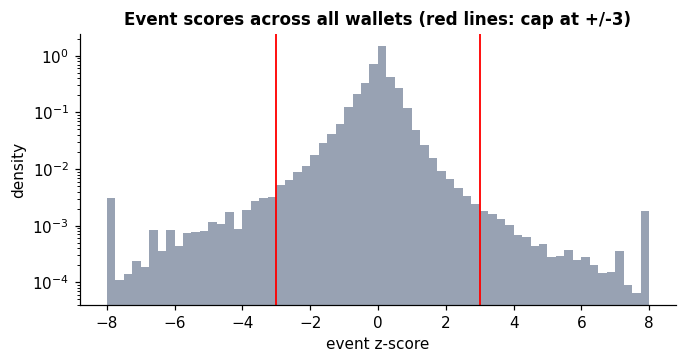

In [5]:
d = ev_events[["wallet", "event_key", "c", "V", "volume", "z", "z_clipped"]]
print("Scores for the demo wallet's events (c = profit in dollars, V = luck variance):")
display(d[d.wallet == DEMO].sort_values("z", ascending=False).head(8).round(3))

z = ev_events["z"].dropna().clip(-8, 8)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(z, bins=np.arange(-8, 8.25, 0.25), color=GREY, density=True)
for v in (-3, 3): ax.axvline(v, color="red", lw=1.2)
ax.set(title="Event scores across all wallets (red lines: cap at +/-3)", xlabel="event z-score", ylabel="density", yscale="log")
plt.show()

## 4. Flagging wallets

**What this does.** For each wallet with at least the minimum number of events:
1. combine its event scores into one **evidence score** `Z` (the sum of its event scores divided by the square root of its number of events);
2. compare the **spread** of `Z` across all wallets with what luck predicts, and shrink every score if the spread is wider (this absorbs correlations the formula misses);
3. turn scores into p-values and apply the **Benjamini-Hochberg** correction, which limits false flags to about the false-flag rate `Q`. With thousands of wallets some look good by pure chance, so a plain cut-off would flag many lucky wallets.

**Look for.** On the left, the scores should follow the dashed luck curve in the middle, with a right tail beyond it. The flagged wallets (orange) are the far right. On the right, points above the diagonal are higher than luck predicts.

{'eligible_wallets': 4009, 'sigma_hat': 1.0, 'median_Z': 0.1495, 'flagged': 19, 'flag_rate': 0.0047}


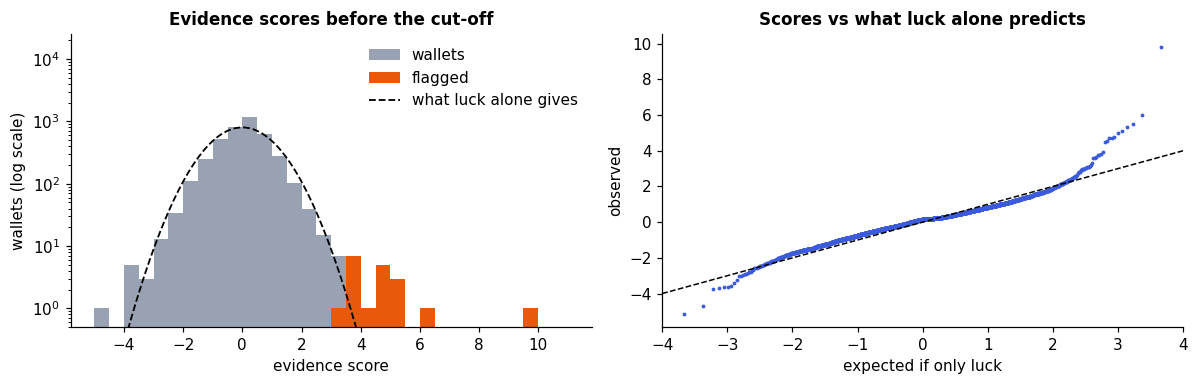

,wallet,n_events,Z_adj,profit,volume,profit_per_dollar
wallet,,,,,,
29646,0xf0b0ef1d6320c6be896b4c9c54dd74407e7f8cab,168,9.783,3080.448,688158.338,0.004
145848,0x4247c89f4a9236a6b5fb24502023bcc98ab1455f,80,6.029,113.698,711.736,0.160
145850,0x7e80fca8bf7a3e61fd8d2bd7f5e585fec457f17a,15,5.470,2389.287,6231.718,0.383
117334,0x2d4bf8f846bf68f43b9157bf30810d334ac6ca7a,56,5.347,28193.431,14372.026,1.962
170245,0x9bbd88140ccba06100da00476257d9cffce56e72,43,5.099,13562.146,11872.266,1.142
213160,0x7ac83882979ccb5665cea83cb269e558b55077cd,31,4.974,13131.062,243946.371,0.054
192546,0x78a19803306d350cd1120bb07fcfe91a665be6bd,24,4.752,7269.713,3989.543,1.822
117852,0xbcc276705fb6d5a22e4aef994ede92f109918c9a,37,4.737,465.947,43960.782,0.011
144182,0x77bdeb3f229bf6d826d20dbd5f0c7972c32ae48f,50,4.701,152.710,12107.291,0.013


In [6]:
stats_form = st.wallet_stats(form_events, MIN_EVENTS)
flagged_ev = st.flag_wallets(stats_form, q=Q, method="BH")
rep = st.calibration_report(flagged_ev)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rep.items() if k in
       ("eligible_wallets", "flagged", "flag_rate", "sigma_hat", "median_Z")})

el = flagged_ev[flagged_ev.eligible]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.arange(-5, 11.5, 0.5)
ax[0].hist(el.Z_adj[~el.informed], bins=bins, color=GREY, label="wallets")
ax[0].hist(el.Z_adj[el.informed], bins=bins, color=AMBER, label="flagged")
x = np.linspace(-5, 11, 300); ax[0].plot(x, len(el) * 0.5 * stats.norm.pdf(x), "k--", lw=1.2, label="what luck alone gives")
ax[0].set(title="Evidence scores before the cut-off", xlabel="evidence score", ylabel="wallets (log scale)", yscale="log", ylim=(0.5, None)); ax[0].legend(frameon=False)
zs = np.sort(el.Z_adj.to_numpy()); qn = stats.norm.ppf((np.arange(1, len(zs) + 1) - 0.5) / len(zs))
ax[1].plot(qn, zs, ".", ms=3, color=BLUE); ax[1].plot([-4, 4], [-4, 4], "k--", lw=1)
ax[1].set(title="Scores vs what luck alone predicts", xlabel="expected if only luck", ylabel="observed", xlim=(-4, 4))
plt.tight_layout(); plt.show()

top = flagged_ev[flagged_ev.informed].sort_values("Z_adj", ascending=False).head(10).copy()
top.insert(0, "wallet", [name_of(c) for c in top.index])
top[["wallet", "n_events", "Z_adj", "profit", "volume", "profit_per_dollar"]].round(3)

## 5. Check 1: false flags

A flagging method is only useful if it **does not flag lucky wallets**. Two tests:

- **Placebo.** On crypto up/down markets no one can have private information, so almost no wallets should be flagged. The earlier, simpler test flagged **4.5%** of wallets there, which showed it was too lenient.
- **Simulated markets.** We generate fake markets with *no* skilled traders (a correct method flags none) and with 60 *planted* skilled traders (it should find them without false flags). The stricter rule (Benjamini-Yekutieli, BY) is shown for comparison.

**Look for.** The placebo flag rate should be well under 1%. In the no-skill simulation the flag count should be 0. With planted traders, "precision" (share of flags that are truly skilled) should be 100%; "recall" (share of skilled traders found) is lower on purpose, because the test is strict.

In [7]:
form_pl = ev_placebo[ev_placebo.period_time < split_ts]
flagged_pl = st.flag_wallets(st.wallet_stats(form_pl, MIN_EVENTS), q=Q, method="BH")
tbl = pd.DataFrame({
    "eligible wallets": [int(flagged_ev.eligible.sum()), int(flagged_pl.eligible.sum())],
    "flagged": [int(flagged_ev.informed.sum()), int(flagged_pl.informed.sum())]}, index=[MAIN_LABEL, "placebo"])
tbl["flag rate"] = (tbl["flagged"] / tbl["eligible wallets"]).map("{:.2%}".format)
print("Old (lenient) test flagged 4.5% of placebo wallets. Current test:")
display(tbl)

sim_check = r2.synthetic_validation(n_seeds=1)
rows = [dict(world="no skilled traders", **{k: r[k] for k in ("method", "flagged", "flag_rate")}) for r in sim_check["noise_only"]] + \
       [dict(world="60 planted skilled traders", **{k: r.get(k) for k in ("method", "flagged", "flag_rate", "recall", "precision")}) for r in sim_check["planted"]]
pd.DataFrame(rows).round(3)

Old (lenient) test flagged 4.5% of placebo wallets. Current test:


,eligible wallets,flagged,flag rate
main sample,4009,19,0.47%
placebo,3944,21,0.53%


,world,method,flagged,flag_rate,recall,precision
0,no skilled traders,BH,0,0.000,NaN,NaN
1,no skilled traders,BY,0,0.000,NaN,NaN
2,60 planted skilled traders,BH,18,0.014,0.3,1.0
3,60 planted skilled traders,BY,0,0.000,0.0,NaN


## 6. Check 2: do high scorers keep winning?

**What this does.** The real test. Using **only events before the cut-off**, every wallet got a score. Now we look at what the same wallets earned on events **after** the cut-off, which they were never scored on.

**Measures.**
- **Rank correlation** between earlier score and later result: 0 means no relationship, 1 means perfect.
- **AUC**: the chance that a wallet that beat prices later had a higher earlier score than one that did not (0.5 is a coin flip). Trading volume alone is shown as a baseline.
- **Score groups**: wallets split into 10 groups by earlier score; the chart shows how much each group beat prices later (0 = matched prices).

**Look for.** A line that rises across groups means the score predicts later results. Compare the main sample with the placebo. In the real data the top group does about as well on both samples, and the main sample's line is steeper mainly because low scorers keep underperforming. That is why we claim *persistent outperformance*, not private information.

,main sample,placebo
wallets scored later,2887,1367
flagged,19,21
rank correlation,0.238,0.068
95% CI,0.20 to 0.28,0.02 to 0.12
AUC (score),0.652,0.546
AUC (volume only),0.501,0.552
flagged that beat prices later,95%,100%
all wallets that beat prices later,58%,59%


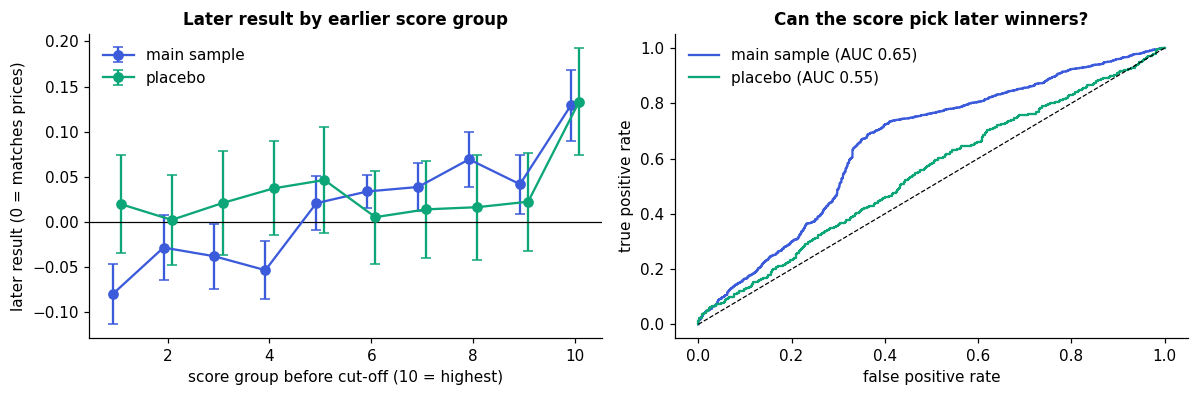

Top group's later result: main sample +0.13, placebo +0.13 | bottom group: main sample -0.08, placebo +0.02


In [8]:
kw = dict(min_events=MIN_EVENTS, min_eval_events=MIN_EVAL_EVENTS)
m_ev, panel_ev, dec_ev = me.performance(ev_events, SPLIT, **kw)
m_pl, panel_pl, dec_pl = me.performance(ev_placebo, SPLIT, **kw)

def row(m):
    s = m["spearman_Z_vs_eval_mean_z"]
    return {"wallets scored later": m["wallets_scored_out_of_sample"], "flagged": m["flagged"],
            "rank correlation": round(s["rho"], 3), "95% CI": f"{s['ci95'][0]:.2f} to {s['ci95'][1]:.2f}",
            "AUC (score)": round(m["auc_beat_prices"]["Z"], 3), "AUC (volume only)": round(m["auc_beat_prices"]["volume_only"], 3),
            "flagged that beat prices later": f"{m.get('flagged_precision_beat_prices', float('nan')):.0%}",
            "all wallets that beat prices later": f"{m['base_rate_beat_prices']:.0%}"}
display(pd.DataFrame({MAIN_LABEL: row(m_ev), "placebo": row(m_pl)}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for name, p, c in ((MAIN_LABEL, panel_ev, BLUE), ("placebo", panel_pl, TEAL)):
    g = p.groupby("decile")["eval_mean_z"]; mean, err = g.mean(), g.apply(lambda s: 1.96 * s.std(ddof=1) / np.sqrt(len(s)))
    ax[0].errorbar(mean.index + (0.08 if name == "placebo" else -0.08), mean, yerr=err, marker="o", color=c, capsize=3, label=name)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set(title="Later result by earlier score group", xlabel="score group before cut-off (10 = highest)", ylabel="later result (0 = matches prices)"); ax[0].legend(frameon=False)
from sklearn.metrics import roc_curve, roc_auc_score
for name, p, c in ((MAIN_LABEL, panel_ev, BLUE), ("placebo", panel_pl, TEAL)):
    if p.beat_prices.nunique() > 1:
        f, t, _ = roc_curve(p.beat_prices, p.Z); ax[1].plot(f, t, color=c, label=f"{name} (AUC {roc_auc_score(p.beat_prices, p.Z):.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set(title="Can the score pick later winners?", xlabel="false positive rate", ylabel="true positive rate"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print("Top group's later result: main sample %+.2f, placebo %+.2f | bottom group: main sample %+.2f, placebo %+.2f" %
      (dec_ev.mean_eval_mean_z.iloc[-1], dec_pl.mean_eval_mean_z.iloc[-1], dec_ev.mean_eval_mean_z.iloc[0], dec_pl.mean_eval_mean_z.iloc[0]))

## 7. Accuracy and PnL: informed vs random vs average wallets

**What this does.** Compares three groups of wallets on what they did **after the cut-off**, on events they were never scored on:
- **Informed**: the wallets flagged from earlier events.
- **Random**: for each informed wallet, a randomly chosen *unflagged* wallet of similar size (same trading volume and number of events). We repeat the random pick **1,000 times**, so we get a whole range of what a random group of this size earns, not one lucky draw.
- **Average**: every other eligible wallet.

**Measures (all after the cut-off).**
- **Event accuracy**: the share of events in which the wallet made money. Accuracy here means "was the bet right".
- **Average later event score**: 0 means the wallet only matched market prices; above 0 means it beat them.
- **PnL** (profit and loss, in dollars, after fees): the total, per wallet, and **per dollar traded** (so big and small groups compare fairly).
- **"Beat X% of random draws"**: how often the informed group's number beats the random groups'. Near 100% means a random group almost never does as well.

**A second view of accuracy** treats the flag as a prediction ("this wallet will beat prices later") and reports the standard classification numbers. Because only a few wallets are flagged, *overall* accuracy is mostly set by the many unflagged wallets, so compare it with the "always guess no" baseline and read precision (how many flags are right) alongside recall (how many winners are caught).

**Look for.** Informed above random and average on every measure, with the random range (5th to 95th percentile) not covering the informed value. With only about 20 flagged wallets, expect wide ranges.

In [9]:
def build_panel(ev, flagged):
    # one row per eligible wallet: formation stats + what it did after the cut-off
    evl = ev[ev.period_time >= split_ts].dropna(subset=["z_clipped"]).copy()
    evl["win"] = (evl.c > 0).astype(int)
    g = evl.groupby("wallet")
    w = pd.DataFrame({"eval_events": g.size(), "eval_wins": g["win"].sum(), "eval_pnl": g["c"].sum(),
                      "eval_volume": g["volume"].sum(), "eval_mean_z": g["z_clipped"].mean()})
    p = flagged[flagged.eligible].join(w, how="inner")
    return p[p.eval_events >= MIN_EVAL_EVENTS].copy()

def matched_random_draws(p, n_draws=1000, seed=0):
    # for each informed wallet, a random unflagged wallet with similar volume and number of events
    rng = np.random.default_rng(seed)
    vb = pd.qcut(np.log1p(p["volume"]), q=min(10, p["volume"].nunique()), duplicates="drop", labels=False)
    nb = pd.qcut(p["n_events"].rank(method="first"), q=min(5, len(p)), duplicates="drop", labels=False)
    cell = pd.Series(vb.astype(int).astype(str) + "_" + nb.astype(int).astype(str), index=p.index)
    pool = {k: v.index.to_numpy() for k, v in p[~p.informed].groupby(cell[~p.informed])}
    keep = [i for i in p.index[p.informed] if cell[i] in pool]
    return [np.array([rng.choice(pool[cell[i]]) for i in keep]) for _ in range(n_draws)], keep

def metrics(d):
    return {"wallets": len(d), "later events": int(d.eval_events.sum()),
            "event accuracy (share of events with a profit)": d.eval_wins.sum() / d.eval_events.sum(),
            "average later event score (0 = matches prices)": d.eval_mean_z.mean(),
            "PnL per $ traded": d.eval_pnl.sum() / d.eval_volume.sum(),
            "total PnL ($)": d.eval_pnl.sum(), "PnL per wallet, mean ($)": d.eval_pnl.mean(),
            "PnL per wallet, median ($)": d.eval_pnl.median(), "share of wallets with a profit": (d.eval_pnl > 0).mean()}

def compare_groups(ev, flagged, n_draws=1000):
    p = build_panel(ev, flagged)
    draws, keep = matched_random_draws(p, n_draws)
    inf = metrics(p.loc[keep]); avg = metrics(p[~p.informed])
    rnd = pd.DataFrame([metrics(p.loc[ids]) for ids in draws])
    return p, inf, avg, rnd

groups = {}
for name, ev, fl in (("events", ev_events, flagged_ev), ("placebo", ev_placebo, flagged_pl)):
    pp = build_panel(ev, fl)
    if pp.informed.sum() == 0:                       # e.g. the simulated placebo: nobody is flagged, which is the right answer
        print(f"{LABEL[name]}: no flagged wallets with later results, so there is no informed group to compare.")
        continue
    groups[name] = compare_groups(ev, fl)

def fmt(k, v):
    if "($)" in k: return f"${v:,.0f}"
    if "share" in k or "accuracy" in k: return f"{v:.1%}"
    if "per $" in k: return f"{v:.2%}"
    if "score" in k: return f"{v:+.3f}"
    return f"{v:,.0f}"

for name, (p, inf, avg, rnd) in groups.items():
    rows = []
    for k in inf:
        lo, hi = rnd[k].quantile([0.05, 0.95])
        beat = (inf[k] > rnd[k]).mean()
        rows.append({"measure": k, "informed": fmt(k, inf[k]), "random (average of 1,000 draws)": fmt(k, rnd[k].mean()),
                     "random 5th to 95th percentile": f"{fmt(k, lo)} to {fmt(k, hi)}", "average wallet group": fmt(k, avg[k]),
                     "informed beat this % of random draws": "" if k in ("wallets", "later events") else f"{beat:.0%}"})
    print(f"\n=== {LABEL[name].upper()}: after the cut-off, {inf['wallets']} informed wallets vs matched random vs {avg['wallets']:,} other wallets ===")
    display(pd.DataFrame(rows).set_index("measure"))


=== MAIN SAMPLE: after the cut-off, 19 informed wallets vs matched random vs 2,868 other wallets ===


,informed,"random (average of 1,000 draws)",random 5th to 95th percentile,average wallet group,informed beat this % of random draws
measure,,,,,
wallets,19,19,19 to 19,"2,868",
later events,738,696,455 to 966,"47,847",
event accuracy (share of events with a profit),55.8%,52.7%,42.0% to 63.5%,52.9%,68%
average later event score (0 = matches prices),+0.443,-0.008,-0.110 to +0.089,+0.010,100%
PnL per $ traded,7.09%,0.88%,-4.15% to 4.92%,2.07%,99%
total PnL ($),"$163,871","$91,883","$-177,694 to $543,774","$5,784,665",81%
"PnL per wallet, mean ($)","$8,625","$4,836","$-9,352 to $28,620","$2,017",81%
"PnL per wallet, median ($)",$636,$41,$-21 to $178,$0,99%
share of wallets with a profit,89.5%,57.5%,42.1% to 73.7%,56.1%,100%



=== PLACEBO: after the cut-off, 6 informed wallets vs matched random vs 1,361 other wallets ===


,informed,"random (average of 1,000 draws)",random 5th to 95th percentile,average wallet group,informed beat this % of random draws
measure,,,,,
wallets,6,6,6 to 6,"1,361",
later events,329,191,91 to 306,"30,449",
event accuracy (share of events with a profit),58.1%,59.5%,47.9% to 73.7%,58.1%,46%
average later event score (0 = matches prices),+0.546,+0.070,-0.089 to +0.260,+0.030,100%
PnL per $ traded,12.82%,1.36%,-5.64% to 9.32%,1.05%,98%
total PnL ($),"$5,945",$44,"$-3,024 to $2,298","$40,031",98%
"PnL per wallet, mean ($)",$991,$7,$-504 to $383,$29,98%
"PnL per wallet, median ($)",$159,$21,$-28 to $114,$1,98%
share of wallets with a profit,50.0%,57.0%,33.3% to 83.3%,52.3%,23%


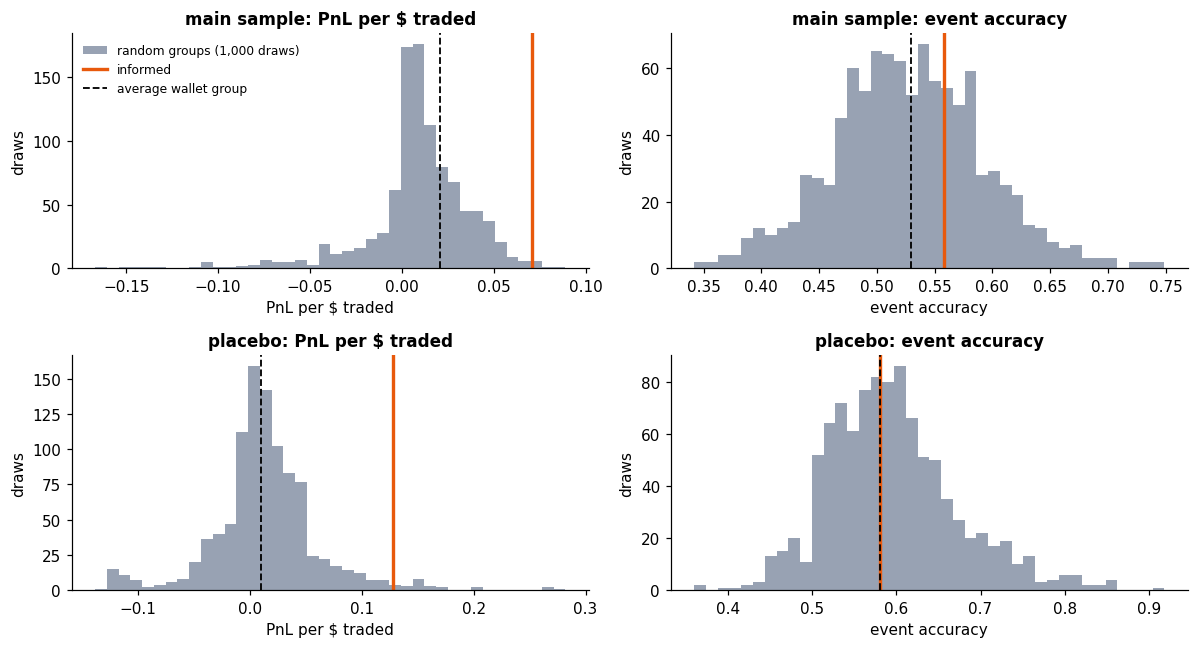

In [10]:
fig, ax = plt.subplots(len(groups), 2, figsize=(11, 3 * len(groups)), squeeze=False)
for r, (name, (p, inf, avg, rnd)) in enumerate(groups.items()):
    for c, k in enumerate(["PnL per $ traded", "event accuracy (share of events with a profit)"]):
        a = ax[r, c]; a.hist(rnd[k], bins=40, color=GREY, label="random groups (1,000 draws)")
        a.axvline(inf[k], color=AMBER, lw=2.2, label="informed"); a.axvline(avg[k], color="k", ls="--", lw=1.2, label="average wallet group")
        a.set(title=f"{LABEL[name]}: {k.split(' (')[0]}", xlabel=k.split(' (')[0], ylabel="draws")
        if r == 0 and c == 0: a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# The flag as a prediction: "this wallet will beat market prices later"
def confusion(p):
    y = (p.eval_mean_z > 0); f = p.informed
    tp, fp, fn, tn = int((f & y).sum()), int((f & ~y).sum()), int((~f & y).sum()), int((~f & ~y).sum())
    n = tp + fp + fn + tn
    return {"wallets scored later": n, "flagged and beat prices later (right)": tp, "flagged but did not (wrong)": fp,
            "not flagged but beat prices later (missed)": fn, "not flagged and did not": tn,
            "overall accuracy": (tp + tn) / n, "baseline: always guess 'no'": max(y.mean(), 1 - y.mean()) if False else 1 - y.mean(),
            "precision (flags that are right)": tp / (tp + fp) if tp + fp else float("nan"),
            "recall (winners the flag catches)": tp / (tp + fn) if tp + fn else float("nan"),
            "specificity (non-winners left unflagged)": tn / (tn + fp) if tn + fp else float("nan"),
            "all wallets that beat prices later": y.mean()}
conf = pd.DataFrame({LABEL[name]: confusion(g[0]) for name, g in groups.items()})
for idx in conf.index:
    if any(s in idx for s in ("accuracy", "baseline", "precision", "recall", "specificity", "all wallets")):
        conf.loc[idx] = [f"{v:.1%}" for v in conf.loc[idx].astype(float)]
    else:
        conf.loc[idx] = [f"{int(v):,}" for v in conf.loc[idx].astype(float)]
display(conf)
tk = pd.DataFrame({LABEL[name]: pd.Series(g[0].sort_values("Z", ascending=False).eval_mean_z.gt(0).rolling(1).mean().index.size and
                                   {k: g[0].sort_values("Z", ascending=False).head(k).eval_mean_z.gt(0).mean() for k in (25, 50, 100, 200, 500) if len(g[0]) >= k})
                   for name, g in groups.items()})
print("Share of the top-k wallets by earlier score that beat prices later (all wallets: see last row above):")
display(tk.map(lambda v: "" if pd.isna(v) else f"{v:.0%}"))

,main sample,placebo
wallets scored later,"2,887","1,367"
flagged and beat prices later (right),18,6
flagged but did not (wrong),1,0
not flagged but beat prices later (missed),"1,644",794
not flagged and did not,"1,224",567
overall accuracy,43.0%,41.9%
baseline: always guess 'no',42.4%,41.5%
precision (flags that are right),94.7%,100.0%
recall (winners the flag catches),1.1%,0.8%
specificity (non-winners left unflagged),99.9%,100.0%


Share of the top-k wallets by earlier score that beat prices later (all wallets: see last row above):


,main sample,placebo
25,92%,84%
50,84%,76%
100,79%,67%
200,73%,63%
500,68%,62%


### Trade-level accuracy and PnL (main sample)

The table above works per wallet and per event. This view works per **trade**: the share of individual trades that made money, the typical return per trade, and PnL. It reads the actual fills of the informed wallets, of one random matched draw, and of up to 2,000 other wallets (the "average"), and counts only trades in events **after** the cut-off.

**Look for.** Read the **median** return and accuracy first: mean returns are inflated by long shots that win. PnL per dollar traded puts all groups on the same footing. A group can have a high win rate and low PnL (many small wins, a few big losses) or the reverse.

In [12]:
import pyarrow.parquet as pq
ekey, ptime = st.event_keys(mk_ev), st.period_times(mk_ev)
p_ev, inf_ev, avg_ev, rnd_ev = groups["events"]
draws, keep = matched_random_draws(p_ev, n_draws=1)
informed_ids = list(p_ev.index[p_ev.informed]); random_ids = list(draws[0])
rng = np.random.default_rng(1); others = p_ev.index[~p_ev.informed].to_numpy()
average_ids = list(rng.choice(others, size=min(2000, len(others)), replace=False))

def group_trades(codes):
    codes = [int(c) for c in codes]
    if SIM:
        f = fills_ev[fills_ev.wallet.isin(codes)]
    else:
        f = pq.read_table(EVENTS_DIR / "fills_clean.parquet", columns=["wallet", "condition_id", "dir0", "size", "p0", "usdc", "fee_usdc"],
                          filters=[("wallet", "in", codes)]).to_pandas()
    f = f[f.condition_id.map(ekey).map(ptime) >= split_ts]            # only events after the cut-off
    t = tr.add_trade_returns(f, mk_ev)
    return t[t.resolved]

def trade_stats(t, n_wallets):
    return {"wallets": n_wallets, "trades after the cut-off": f"{len(t):,}",
            "trade accuracy (share of trades that made money)": f"{(t.trade_pnl > 0).mean():.1%}",
            "median return per trade": f"{t.trade_return.median():+.1%}", "mean return per trade": f"{t.trade_return.mean():+.1%}",
            "PnL per $ traded": f"{t.trade_pnl.sum() / t.usdc.sum():+.2%}", "total PnL ($)": f"${t.trade_pnl.sum():,.0f}",
            "PnL per wallet ($)": f"${t.trade_pnl.sum() / n_wallets:,.0f}"}
trade_table = pd.DataFrame({
    "informed": trade_stats(group_trades(informed_ids), len(informed_ids)),
    "random matched (one draw)": trade_stats(group_trades(random_ids), len(random_ids)),
    f"average (random sample of {len(average_ids):,} others)": trade_stats(group_trades(average_ids), len(average_ids))})
trade_table

,informed,random matched (one draw),"average (random sample of 2,000 others)"
wallets,19,19,2000
trades after the cut-off,"71,999","33,726","1,672,109"
trade accuracy (share of trades that made money),46.7%,55.2%,55.8%
median return per trade,-100.0%,+0.2%,+0.2%
mean return per trade,+3.9%,-10.5%,-3.2%
PnL per $ traded,+7.74%,+2.96%,+2.30%
total PnL ($),"$193,684","$55,428","$5,602,871"
PnL per wallet ($),"$10,194","$2,917","$2,801"


## 8. Check 3: stability over time and across settings

A result that appears for one cut-off date or one setting could be an accident. Two robustness checks:

- **Walk-forward.** Repeat the test with different cut-off dates, each time scoring wallets only on events before the date and checking the following window.
- **Sensitivity grid.** Re-run with different cut-off dates, minimum events per wallet, and strictness (BH or the stricter BY). Each point is "flagged wallets minus matched wallets" (similar volume and activity) on later events, with a 95% interval.

**Look for.** Walk-forward bars that stay similar across windows. In the grid, dots to the right of zero mean flagged wallets did better; compare how often the main sample and the placebo are clearly right of zero. Flagged groups are small (tens of wallets), so the intervals are wide.

split  flagged  scored_flagged  spearman  auc_Z  \
main sample 0  2026-04-01        7               7     0.227  0.644   
            1  2026-06-01       19              19     0.252  0.657   
            2  2026-08-01       25              17     0.213  0.628   
placebo     0  2026-04-01       15               8     0.118  0.563   
            1  2026-06-01       21               5     0.072  0.542   
            2  2026-08-01       41              17     0.132  0.568   

               diff_vs_matched  
main sample 0            0.686  
            1            0.331  
            2            0.409  
placebo     0            0.634  
            1            0.648  
            2           -0.054

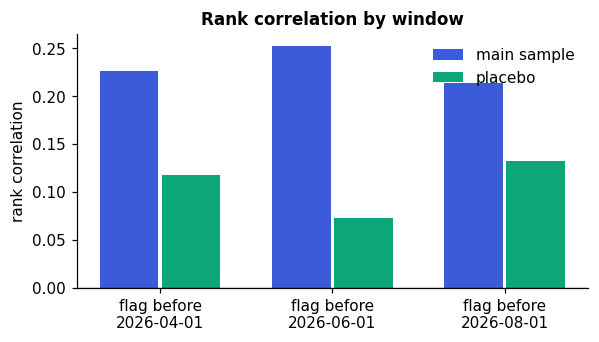

In [13]:
wf_ev = me.walk_forward(ev_events, WF_STARTS, WF_DAYS, **kw); wf_pl = me.walk_forward(ev_placebo, WF_STARTS, WF_DAYS, **kw)
display(pd.concat({MAIN_LABEL: wf_ev, "placebo": wf_pl})[["split", "flagged", "scored_flagged", "spearman", "auc_Z", "diff_vs_matched"]].round(3))
x = np.arange(len(WF_STARTS)); fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(x - 0.18, wf_ev.spearman, 0.34, color=BLUE, label=MAIN_LABEL); ax.bar(x + 0.18, wf_pl.spearman, 0.34, color=TEAL, label="placebo")
ax.set_xticks(x, [f"flag before\n{s}" for s in WF_STARTS]); ax.axhline(0, color="k", lw=0.8)
ax.set(title="Rank correlation by window", ylabel="rank correlation"); ax.legend(frameon=False); plt.show()

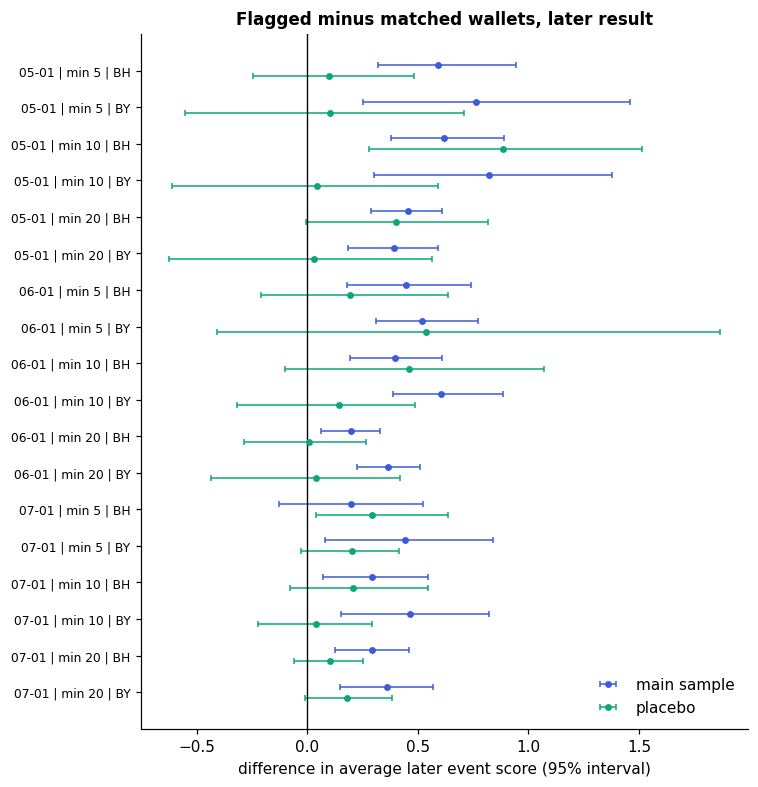

main sample: difference above zero in 18 of 18 settings; interval above zero in 17
placebo: difference above zero in 18 of 18 settings; interval above zero in 2


In [14]:
grid = dict(splits=SENS_SPLITS, min_events=SENS_MIN, methods=["BH", "BY"], qs=[0.10])
sens = {"events": pd.DataFrame(r2.sensitivity(ev_events, **grid)), "placebo": pd.DataFrame(r2.sensitivity(ev_placebo, **grid))}
fig, ax = plt.subplots(figsize=(7, 0.32 * len(sens["events"]) + 1.5))
labels = [f"{r.split[5:]} | min {r.min_events} | {r.method}" for r in sens["events"].itertuples()]
for name, c, off in (("events", BLUE, -0.15), ("placebo", TEAL, 0.15)):
    d = sens[name].copy(); d["eval_mean_z_diff_vs_matched"] = pd.to_numeric(d.eval_mean_z_diff_vs_matched, errors="coerce")
    ci = np.array([(x if x else [np.nan, np.nan]) for x in d.eval_mean_z_diff_ci95], dtype=float)
    y = np.arange(len(d)) + off
    ax.errorbar(d.eval_mean_z_diff_vs_matched, y, xerr=[d.eval_mean_z_diff_vs_matched - ci[:, 0], ci[:, 1] - d.eval_mean_z_diff_vs_matched],
                fmt="o", ms=3.5, color=c, lw=1, capsize=2, label=LABEL[name])
ax.axvline(0, color="k", lw=0.9); ax.set_yticks(range(len(labels)), labels, fontsize=8); ax.invert_yaxis()
ax.set(title="Flagged minus matched wallets, later result", xlabel="difference in average later event score (95% interval)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
for name, d in sens.items():
    ok = pd.to_numeric(d.eval_mean_z_diff_vs_matched, errors="coerce").dropna(); lo = [x[0] for x in d.eval_mean_z_diff_ci95 if x and x[0] is not None and x[0] == x[0]]
    print(f"{LABEL[name]}: difference above zero in {int((ok > 0).sum())} of {len(ok)} settings; interval above zero in {int(sum(v > 0 for v in lo))}")

### 8b. How strict should the false-flag rate (`q`) be?

**What `q` is.** The test lets about a fraction `q` of its flags be wrong (the Benjamini-Hochberg rate). We use **q = 10%**. A larger `q` flags more wallets, but it also lets more lucky wallets through. This section tests whether 10% is a defensible choice by re-running everything at **q = 5%, 10%, 20% and 30%**, keeping the cut-off date and minimum events fixed.

**Three pieces of evidence.**
1. **Real data: flags and later results.** How many wallets are flagged in the main sample and in the placebo, and whether the flagged wallets still beat matched wallets later (95% interval).
2. **Real data: the placebo as a false-flag check.** The placebo is where private information is impossible, so flags there are the closest thing to measured false flags. If loosening `q` adds flags mostly on the placebo, the extra flags are not evidence of information.
3. **Simulation: what loosening buys.** In simulated worlds with 60 planted skilled traders we know who is skilled, so we can measure **recall** (share of skilled traders found) and **precision** (share of flags that are skilled), plus the flag rate in a world with **no** skilled traders. The planted traders are unrealistically easy to find (many events each), so read the simulation as showing the *direction* of the trade-off, not realistic numbers.

**What would defend q = 10%.** The main-sample result stays positive across `q`; the placebo's flag count does not start growing much faster than the main sample's near our choice; and the simulation shows what a stricter or looser `q` trades away.

In [15]:
QS = [0.05, 0.10, 0.20, 0.30]
rows = []
for name, e in (("events", ev_events), ("placebo", ev_placebo)):
    for r in r2.sensitivity(e, [str(split_ts.date())], [MIN_EVENTS], ["BH"], QS):
        ci = r["eval_mean_z_diff_ci95"]
        rows.append({"sample": LABEL[name], "q": r["q"], "eligible wallets": r["eligible"], "flagged": r["flagged"], "flagged per 1,000 wallets": 1000 * r["flag_rate"],
                     "flagged minus matched, later": pd.to_numeric(r["eval_mean_z_diff_vs_matched"], errors="coerce"),
                     "ci_lo": ci[0] if ci else np.nan, "ci_hi": ci[1] if ci else np.nan})
q_real = pd.DataFrame(rows)
shown = q_real.copy()
shown["flagged per 1,000 wallets"] = shown["flagged per 1,000 wallets"].round(1)
shown["95% interval"] = [("" if pd.isna(a) else f"{a:+.2f} to {b:+.2f}") for a, b in zip(q_real.ci_lo, q_real.ci_hi)]
shown["flagged minus matched, later"] = shown["flagged minus matched, later"].map(lambda v: "" if pd.isna(v) else f"{v:+.2f}")
display(shown.drop(columns=["ci_lo", "ci_hi"]).set_index(["sample", "q"]))

eligible wallets  flagged  flagged per 1,000 wallets  \
sample      q                                                            
main sample 0.05              4009       18                        4.5   
            0.10              4009       19                        4.7   
            0.20              4009       25                        6.2   
            0.30              4009       33                        8.2   
placebo     0.05              3944       18                        4.6   
            0.10              3944       21                        5.3   
            0.20              3944       30                        7.6   
            0.30              3944       66                       16.7   

                 flagged minus matched, later    95% interval  
sample      q                                                  
main sample 0.05                        +0.41  +0.18 to +0.65  
            0.10                        +0.40  +0.19 to +0.61  
            0.20                        +0.23  +0.02 to +0.44  
            0.30                        +0.25  +0.07 to +0.42  
placebo     0.05                        -0.00  -0.47 to +0.43  
            0.10                        +0.46  -0.10 to +1.07  
            0.20                        +0.58  +0.11 to +1.10  
            0.30                        +0.56  +0.24 to +0.91

,recall (skilled traders found),precision (flags that are skilled),wallets flagged,flag rate with no skilled traders
q,,,,
0.05,4%,100%,2.3,0.00%
0.10,24%,100%,14.7,0.00%
0.20,58%,97%,35.7,0.00%
0.30,69%,96%,43.0,0.00%


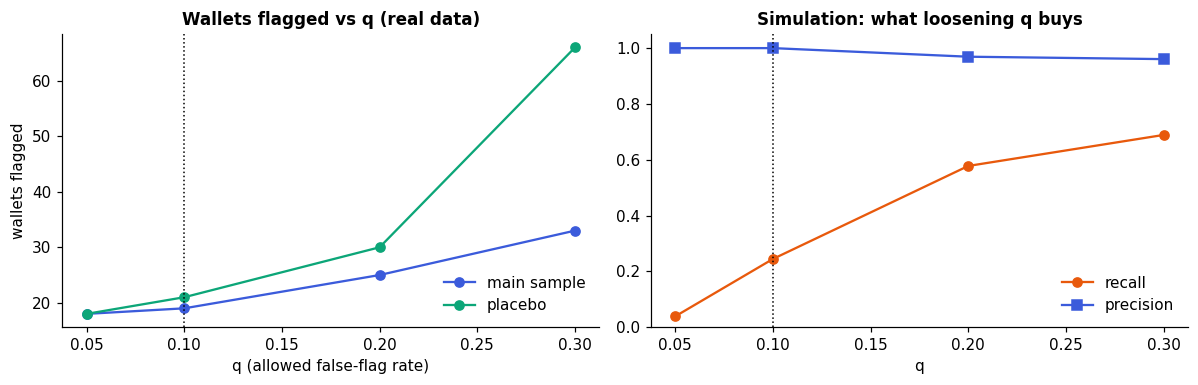

Going from q = 10% to q = 30%: main sample flags 19 -> 33; placebo flags 21 -> 66.
Main-sample interval above zero at q = [0.05, 0.1, 0.2, 0.3] | placebo interval above zero at q = [0.2, 0.3]
Simulation at q = 10%: recall 24%, precision 100%.


In [16]:
def sim_q_table(seeds=(0, 1, 2), min_events=5):
    out = []
    for sd in seeds:
        fills, mk, names, truth = make_sim_world(60, 500 + sd); ev = st.event_table(st.wallet_market_terms(fills, mk), mk)
        fills0, mk0, names0, truth0 = make_sim_world(0, 600 + sd); ev0 = st.event_table(st.wallet_market_terms(fills0, mk0), mk0)
        cut, cut0 = ev.period_time.quantile(0.5), ev0.period_time.quantile(0.5)
        for q in QS:
            s_ = st.flag_wallets(st.wallet_stats(ev[ev.period_time < cut], min_events=min_events), q=q, method="BH")
            s_.index = names[s_.index.to_numpy()].astype(str); s_["truth"] = truth.reindex(s_.index)
            el, fl = s_[s_.eligible], s_[s_.informed]; n_skilled = int((el.truth == "informed").sum())
            s0 = st.flag_wallets(st.wallet_stats(ev0[ev0.period_time < cut0], min_events=min_events), q=q, method="BH")
            out.append({"q": q, "recall (skilled traders found)": (fl.truth == "informed").sum() / max(1, n_skilled),
                        "precision (flags that are skilled)": (fl.truth == "informed").mean() if len(fl) else np.nan,
                        "wallets flagged": len(fl), "flag rate with no skilled traders": s0.informed.sum() / max(1, s0.eligible.sum())})
    return pd.DataFrame(out).groupby("q").mean()
sim_q = sim_q_table()
sim_show = sim_q.copy()
for col, f in (("recall (skilled traders found)", "{:.0%}"), ("precision (flags that are skilled)", "{:.0%}"), ("wallets flagged", "{:.1f}"), ("flag rate with no skilled traders", "{:.2%}")):
    sim_show[col] = sim_show[col].map(lambda v, f=f: "n/a" if pd.isna(v) else f.format(v))
display(sim_show)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, c in (("events", BLUE), ("placebo", TEAL)):
    d = q_real[q_real["sample"] == LABEL[name]]; ax[0].plot(d.q, d.flagged, "o-", color=c, label=LABEL[name])
ax[0].axvline(Q, color="k", ls=":", lw=1); ax[0].set(title="Wallets flagged vs q (real data)", xlabel="q (allowed false-flag rate)", ylabel="wallets flagged"); ax[0].legend(frameon=False)
ax[1].plot(sim_q.index, sim_q["recall (skilled traders found)"], "o-", color=AMBER, label="recall")
ax[1].plot(sim_q.index, sim_q["precision (flags that are skilled)"], "s-", color=BLUE, label="precision")
ax[1].axvline(Q, color="k", ls=":", lw=1); ax[1].set(title="Simulation: what loosening q buys", xlabel="q", ylim=(0, 1.05)); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

m_ = q_real[q_real["sample"] == MAIN_LABEL].set_index("q"); p_ = q_real[q_real["sample"] == "placebo"].set_index("q")
print(f"Going from q = {QS[1]:.0%} to q = {QS[-1]:.0%}: main sample flags {int(m_.flagged[QS[1]])} -> {int(m_.flagged[QS[-1]])}; placebo flags {int(p_.flagged[QS[1]])} -> {int(p_.flagged[QS[-1]])}.")
print("Main-sample interval above zero at q =", [q for q in QS if m_.ci_lo[q] > 0] or "none", "| placebo interval above zero at q =", [q for q in QS if p_.ci_lo[q] > 0] or "none")
print(f"Simulation at q = {Q:.0%}: recall {sim_q.loc[Q, 'recall (skilled traders found)']:.0%}, precision {sim_q.loc[Q, 'precision (flags that are skilled)']:.0%}.")

**How to read it (project run: flag before June 1, 2026).**
- **q = 5%** is too strict: it finds only a small share of skilled traders even in the simulation.
- **q = 10%** (our choice) keeps almost every flag correct in the simulation while finding a meaningful share of skilled traders. On the real data the main sample's flagged wallets beat matched wallets later by +0.40 (95% interval +0.19 to +0.61).
- **q = 20% and 30%** find more skilled traders in the simulation. On the real data they add flags, but the main sample's advantage **shrinks** (+0.40 to about +0.25), meaning the added wallets are weaker, and the **placebo's** flag count grows faster than the main sample's (21 to 66 at q = 30%, against 19 to 33). Placebo wallets cannot have private information, so those extra flags do not add evidence of it.
- **The placebo also looks "positive" at looser q.** At q = 20% and 30% the placebo's flagged wallets also beat matched wallets later, by about as much as the main sample. That is the same caveat as before: the test finds persistent outperformance, and loosening `q` does not make the main sample look any more different from the placebo.
- The simulation's no-skill world flags almost nobody at any `q` (nobody there is skilled, so there is nothing for the correction to let through). That is why the placebo, not the simulation, is the real-data check on false flags.
- **Reporting.** Keep q = 10% as the headline and show this table as the sensitivity analysis. Say plainly that the test is conservative by design: it misses many skilled traders to keep false flags low, and loosening it adds mostly weaker wallets and placebo flags. Only a few tens of wallets are behind each real-data row, so intervals are wide.

## 9. Return per trade and PnL for one wallet

**What this does.** For the demo wallet, expresses every fill as a long position in one outcome and computes
- **return per trade** = (payout - price paid) / price paid. Buying a 10-cent outcome that wins returns +900%; one that loses, -100%.
- **PnL** (profit and loss) = dollars made on the trade, after fees.

**Why we report both.** Returns are per dollar and are inflated by long shots, so read the **median** and the win rate next to the mean. PnL is in dollars and is dominated by a wallet's biggest bets. The flagging test itself uses neither directly (step 3), because both are skewed.

**Look for.** A wallet can have a high mean return and a modest median, or the reverse. Wallets with tiny profit per dollar traded and very many events often look like market makers or bots, not forecasters.

,demo wallet
resolved trades,87260
mean return per trade,-8%
median return per trade,-100%
win rate,47%
total PnL,"$6,118"
dollars traded,"$1,125,818"
PnL per dollar traded,0.54%


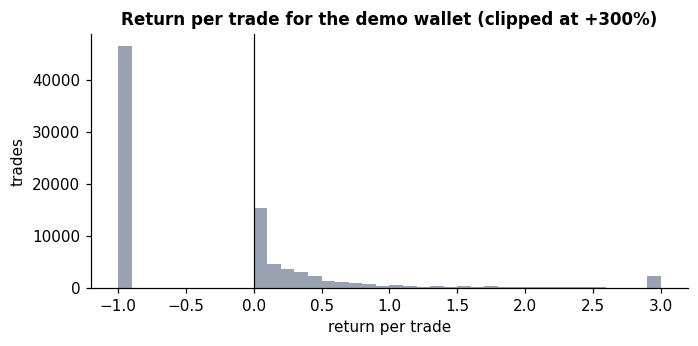

In [17]:
t = tr.add_trade_returns(wf, mk_ev)
res = t[t.resolved]
summary_w = pd.Series({
    "resolved trades": len(res), "mean return per trade": f"{res.trade_return.mean():.0%}",
    "median return per trade": f"{res.trade_return.median():.0%}", "win rate": f"{(res.trade_pnl > 0).mean():.0%}",
    "total PnL": f"${res.trade_pnl.sum():,.0f}", "dollars traded": f"${res.usdc.sum():,.0f}",
    "PnL per dollar traded": f"{res.trade_pnl.sum() / res.usdc.sum():.2%}"})
display(summary_w.to_frame("demo wallet"))
fig, ax = plt.subplots(figsize=(7, 3)); ax.hist(res.trade_return.clip(-1, 3), bins=40, color=GREY)
ax.axvline(0, color="k", lw=0.8); ax.set(title="Return per trade for the demo wallet (clipped at +300%)", xlabel="return per trade", ylabel="trades"); plt.show()

## 10. The live labels, the website and the writeup files

**Live labels.** For the website and live feed we re-score wallets using **all resolved history** (no evaluation split). The live feed then watches only wallets flagged from the past, so it never uses future results. The cell below counts them.

**The other pieces** are scripts run from a terminal, in this order (they read the same saved results this notebook used):

```bash
python run_flagging_v2.py --data data_events/live --placebo data_placebo/live   # steps 4 to 7, saves results_v2/
python evaluate_model.py                                                         # step 6 statistics + figure
python make_report_figures.py                                                    # seven figures, tables, captions -> results_v2/report/
python run_flagging_v2.py --data data_events/live --label-all                    # live labels
python build_dashboard.py --data data_events/live --results results_v2           # website data
python live_feed.py                                                              # own terminal: watches flagged wallets
python -m http.server -d site 8000                                               # own terminal: serves the site at localhost:8000
```

In [18]:
s_all, res_all = st.run_split(ev_events, "2100-01-01", MIN_EVENTS, Q, "BH")     # a cut-off in the far future = use all history
print(f"Using all resolved history: {int(s_all.informed.sum())} likely-informed wallets of {int(s_all.eligible.sum())} eligible")
rep_dir = RESULTS / "report"
print("Writeup files available:", sorted(p.name for p in rep_dir.glob("*"))[:12] if rep_dir.exists() else "none yet (run make_report_figures.py)")

Using all resolved history: 29 likely-informed wallets of 9634 eligible
Writeup files available: ['.DS_Store', 'Archive', 'Archive.zip', 'captions.md', 'fig1_data_overview.pdf', 'fig1_data_overview.png', 'fig2_score_calibration.pdf', 'fig2_score_calibration.png', 'fig3_persistence.pdf', 'fig3_persistence.png', 'fig4_walk_forward.pdf', 'fig4_walk_forward.png']


## 11. What we can and cannot claim

Run the cell to see this run's headline numbers, then read the notes.

In [19]:
card = pd.DataFrame({MAIN_LABEL: row(m_ev), "placebo": row(m_pl)})
card.loc["top score group's later result"] = [f"{dec_ev.mean_eval_mean_z.iloc[-1]:+.2f}", f"{dec_pl.mean_eval_mean_z.iloc[-1]:+.2f}"]
card.loc["bottom score group's later result"] = [f"{dec_ev.mean_eval_mean_z.iloc[0]:+.2f}", f"{dec_pl.mean_eval_mean_z.iloc[0]:+.2f}"]
card

,main sample,placebo
wallets scored later,2887,1367
flagged,19,21
rank correlation,0.238,0.068
95% CI,0.20 to 0.28,0.02 to 0.12
AUC (score),0.652,0.546
AUC (volume only),0.501,0.552
flagged that beat prices later,95%,100%
all wallets that beat prices later,58%,59%
top score group's later result,+0.13,+0.13
bottom score group's later result,-0.08,+0.02


**What the real results support (project run, flag before June 1, 2026).**
- The test is **calibrated**: on the crypto placebo it flags about 0.5% of wallets (the earlier test flagged 4.5%), and in a simulated world with no skilled traders it flags none.
- The score **predicts later results**: rank correlation 0.24 on the main sample (95% interval 0.20 to 0.28) against 0.07 on the placebo; AUC 0.65 against 0.55; stable across three cut-off dates.
- **19 wallets** are flagged in the validation split (29 using all history); 95% of the 19 beat prices later, against 57% of other wallets.

**What they do not support.**
- **Private information.** The top-scoring group does equally well later on both samples (+0.13), so high scorers' persistence could be speed, bots or ordinary skill. The main sample's ranking is stronger mainly because low scorers keep underperforming there.
- **A difference between the flagged groups of the main sample and the placebo.** Each has only about 20 wallets, so the intervals overlap.
- **A dollar-weighted edge.** The edge shows in typical wallets, not in total dollars.

**How to word it.** "Likely informed" or "persistently beat market prices", never "insiders". Always give the interval and the number of wallets behind a number.

In simulated mode the planted traders are skilled by construction, so the notebook should show a clear edge there and none on the no-skill placebo. That is a check that the method works, not a result about Polymarket.

## 12. Exploratory: an index of informed activity, and does it predict anything?

**The idea.** Build an index of *how much of the trading is done by likely-informed wallets*, and test whether it carries any information. This is **exploratory**. It is not part of the validated result above and **is not on the website** until it passes the checks below.

**Two pieces.**
- **Activity index** (how informed the market looks): for each day, the share of dollars traded that came from the flagged wallets. Plotted against the same share for **random matched wallets**, so we can see whether flagged wallets are unusually active at all.
- **Direction signal** (what they are doing): for each market and day, the net direction of the flagged wallets' trades (buying or selling outcome 0). If the index is informative, that direction should predict what prices do next and how the market finally resolves.

**How we test it (out of sample).** Flagged wallets are fixed from the **period before the cut-off**; everything here uses only trades **after** it. For each market-day where the group traded at least $50:
- **Next-day edge** = (the next active day's average price, minus today's average price), counted positive if it moved in the direction the group traded. This does not need the market to resolve.
- **Outcome edge** = (final outcome 1 or 0, minus today's average price), counted positive if the group was on the right side of the resolution.
- Both are in **dollars per share** (0.01 = one cent). Confidence intervals resample whole **events**, because markets in the same event are not independent.
- The same numbers are computed for **200 random matched groups** of wallets (same trading volume and number of events as the flagged ones) to show what a group of ordinary wallets of this size would get.

**What would count as predictive value (decided before looking).** All three: the next-day edge's interval is above zero; the flagged group beats at least 95% of the random groups; and the edge is larger when the flagged share of that day's trading is high than when it is low. The outcome edge is reported too, but it mostly repeats the step 7 finding (flagged wallets keep beating prices), so it counts for less. The placebo is shown alongside: if it looks the same, the index is measuring persistence, not information.

In [20]:
import pyarrow.parquet as pq
N_DRAWS_IDX, MIN_FLOW_USD = 200, 50

def build_index_tables(name, fills_sim, mk, ids):
    # market-day prices for all trading, plus per-wallet net flow for the wallets in `ids`, after the cut-off
    ek, pt = st.event_keys(mk), st.period_times(mk)
    cm = mk.set_index("condition_id")
    event_of = mk.condition_id.map(ek); when = event_of.map(pt)
    conds = [int(c) for c in mk.condition_id[when >= split_ts]]
    cols = ["wallet", "condition_id", "ts", "dir0", "size", "p0", "usdc"]
    if SIM:
        f = fills_sim[cols]
    else:
        d = (EVENTS_DIR if name == "events" else PLACEBO_DIR) / "fills_clean.parquet"
        f = pq.read_table(d, columns=cols, filters=[("condition_id", "in", conds)]).to_pandas()
    f = f[f.condition_id.isin(conds)].copy()
    f["day"] = f.ts.dt.floor("D"); f["pv"] = f.p0.astype(float) * f["size"]
    md = f.groupby(["condition_id", "day"]).agg(tot_usd=("usdc", "sum"), sh=("size", "sum"), pv=("pv", "sum")).reset_index()
    md["vwap"] = md.pv / md.sh
    md = md.sort_values(["condition_id", "day"]); md["vwap_next"] = md.groupby("condition_id").vwap.shift(-1)
    md["Y"] = md.condition_id.map(cm.value_0); md["event"] = md.condition_id.map(ek)
    f = f[f.wallet.isin(set(ids))].copy(); f["flow"] = f.dir0 * f["size"]
    wt = f.groupby(["wallet", "condition_id", "day"]).agg(flow=("flow", "sum"), usd=("usdc", "sum")).reset_index()
    return md, wt

def signals(md, wt_sub):
    g = wt_sub.groupby(["condition_id", "day"]).agg(flow=("flow", "sum"), usd=("usd", "sum")).reset_index()
    g = g[(g.usd >= MIN_FLOW_USD) & (g.flow != 0)].merge(md, on=["condition_id", "day"])
    s = np.sign(g.flow)
    g["next_day_edge"] = s * (g.vwap_next - g.vwap); g["outcome_edge"] = s * (g.Y - g.vwap); g["share"] = g.usd / g.tot_usd
    return g

def edge_summary(g):
    out = {"market-days with a signal": len(g)}
    for col, lab in (("next_day_edge", "next-day"), ("outcome_edge", "outcome")):
        v = g[col].dropna(); out[f"{lab} edge ($ per share)"] = v.mean() if len(v) else np.nan
        out[f"{lab}: share of signals on the right side"] = (v > 0).mean() if len(v) else np.nan
    return out

def cluster_ci(g, col, n=1000, seed=0):
    d = g.dropna(subset=[col]).groupby("event")[col].agg(["sum", "count"])
    if len(d) < 3: return (np.nan, np.nan)
    idx = np.random.default_rng(seed).integers(0, len(d), (n, len(d)))
    m = d["sum"].to_numpy()[idx].sum(1) / d["count"].to_numpy()[idx].sum(1)
    return tuple(np.percentile(m, [2.5, 97.5]))

index_res = {}
for name, mk_, fills_ in (("events", mk_ev, fills_ev if SIM else None), ("placebo", None if SIM and "fills_pl" not in globals() else (mk_pl if SIM else pd.read_parquet(PLACEBO_DIR / "markets_coded.parquet")), fills_pl if SIM else None)):
    if name not in groups:
        print(f"{LABEL[name]}: skipped (no flagged wallets with later results)"); continue
    p_, inf_, avg_, rnd_ = groups[name]
    draws_, keep_ = matched_random_draws(p_, N_DRAWS_IDX)
    md, wt = build_index_tables(name, fills_, mk_, p_.index)
    g_inf = signals(md, wt[wt.wallet.isin(keep_)])
    g_rnd = [signals(md, wt[wt.wallet.isin(ids)]) for ids in draws_]
    rnd_stats = pd.DataFrame([edge_summary(g) for g in g_rnd])
    index_res[name] = dict(md=md, wt=wt, keep=keep_, draws=draws_, g_inf=g_inf, rnd=rnd_stats, inf=edge_summary(g_inf))
    print(f"{LABEL[name]}: {len(keep_)} flagged wallets, {len(g_inf):,} market-days with a signal, {len(md):,} market-days in total")

main sample: 19 flagged wallets, 3,200 market-days with a signal, 64,794 market-days in total


placebo: 6 flagged wallets, 131 market-days with a signal, 162 market-days in total


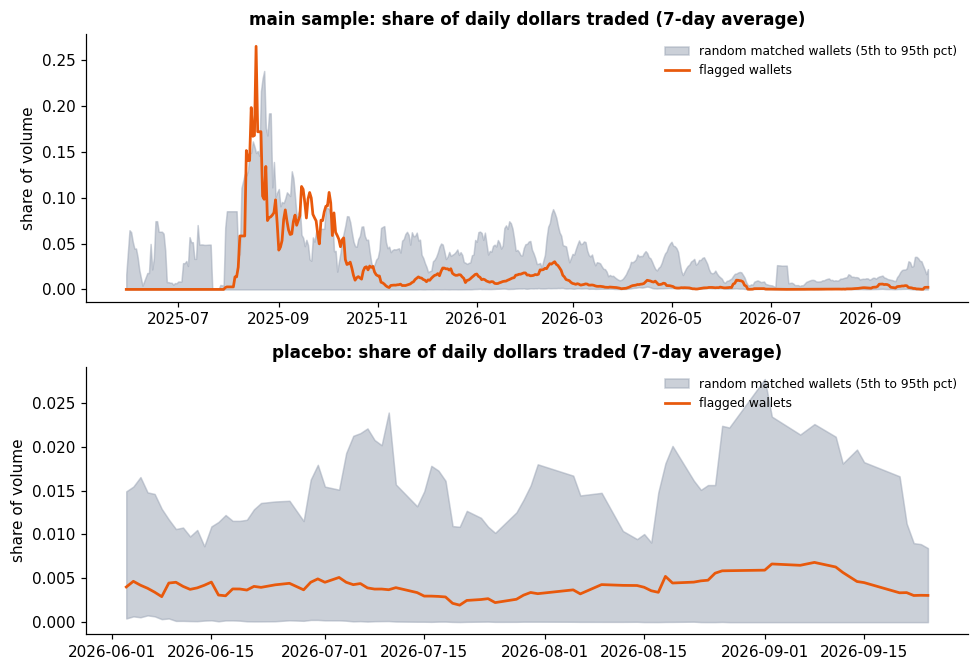

{'main sample': 'flagged wallets trade 1.75% of daily dollars on average', 'placebo': 'flagged wallets trade 0.40% of daily dollars on average'}


In [21]:
# The activity index: share of each day's dollars traded by flagged wallets, vs random matched wallets
def daily_share(md, wt_sub):
    tot = md.groupby("day").tot_usd.sum()
    return (wt_sub.groupby("day").usd.sum().reindex(tot.index).fillna(0) / tot).rolling(7, min_periods=3).mean()

fig, ax = plt.subplots(len(index_res), 1, figsize=(9, 3.1 * len(index_res)), squeeze=False)
for a, (name, R) in zip(ax[:, 0], index_res.items()):
    s_inf = daily_share(R["md"], R["wt"][R["wt"].wallet.isin(R["keep"])])
    band = pd.concat([daily_share(R["md"], R["wt"][R["wt"].wallet.isin(ids)]) for ids in R["draws"][:100]], axis=1)
    a.fill_between(band.index, band.quantile(0.05, axis=1), band.quantile(0.95, axis=1), color=GREY, alpha=0.5, label="random matched wallets (5th to 95th pct)")
    a.plot(s_inf.index, s_inf, color=AMBER, lw=1.8, label="flagged wallets")
    a.set(title=f"{LABEL[name]}: share of daily dollars traded (7-day average)", ylabel="share of volume"); a.legend(frameon=False, fontsize=8)
    R["index_mean"] = float(s_inf.mean())
plt.tight_layout(); plt.show()
print({LABEL[n]: f"flagged wallets trade {R['index_mean']:.2%} of daily dollars on average" for n, R in index_res.items()})

flagged 95% interval (resampling events)  \
sample      measure                                                   
main sample next-day edge  -0.0044               -0.0083 to -0.0010   
            outcome edge   -0.0009               -0.0165 to +0.0145   
placebo     next-day edge  +0.0842                     +nan to +nan   
            outcome edge   +0.0641               +0.0118 to +0.1136   

                          random matched (mean) random 5th to 95th pct  \
sample      measure                                                      
main sample next-day edge               -0.0007     -0.0056 to +0.0029   
            outcome edge                -0.0018     -0.0161 to +0.0129   
placebo     next-day edge               -0.1819     -0.3862 to +0.1390   
            outcome edge                +0.0596     -0.0799 to +0.1735   

                          flagged beat this % of random flagged right side  \
sample      measure                                                          
main sample next-day edge                            8%              47.5%   
            outcome edge                            52%              53.4%   
placebo     next-day edge                            3%             100.0%   
            outcome edge                            49%              61.1%   

                          random right side  
sample      measure                          
main sample next-day edge             50.4%  
            outcome edge              70.1%  
placebo     next-day edge             38.9%  
            outcome edge              63.0%

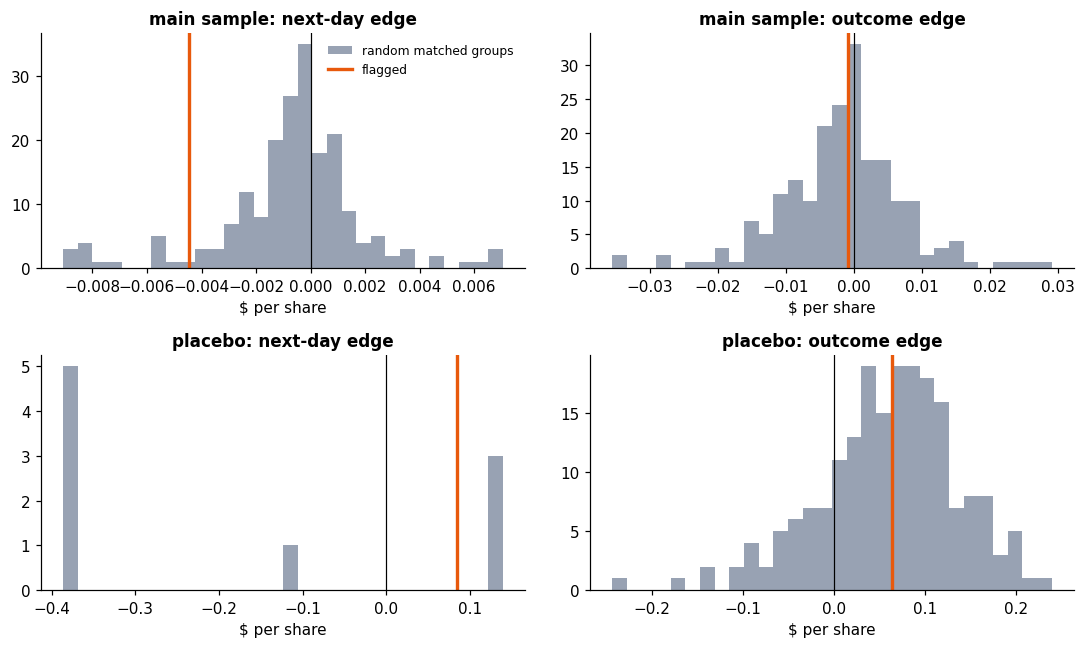

In [22]:
# Does the direction of the flagged wallets' trading predict anything?  Flagged vs 200 random matched groups.
rows = []
for name, R in index_res.items():
    for lab in ("next-day", "outcome"):
        col = f"{lab} edge ($ per share)"; ci = cluster_ci(R["g_inf"], "next_day_edge" if lab == "next-day" else "outcome_edge")
        lo, hi = R["rnd"][col].quantile([0.05, 0.95])
        R[f"beat_{lab}"] = float((R["inf"][col] > R["rnd"][col]).mean()); R[f"ci_{lab}"] = ci
        rows.append({"sample": LABEL[name], "measure": lab + " edge", "flagged": f"{R['inf'][col]:+.4f}", "95% interval (resampling events)": f"{ci[0]:+.4f} to {ci[1]:+.4f}",
                     "random matched (mean)": f"{R['rnd'][col].mean():+.4f}", "random 5th to 95th pct": f"{lo:+.4f} to {hi:+.4f}",
                     "flagged beat this % of random": f"{R[f'beat_{lab}']:.0%}",
                     "flagged right side": f"{R['inf'][f'{lab}: share of signals on the right side']:.1%}",
                     "random right side": f"{R['rnd'][f'{lab}: share of signals on the right side'].mean():.1%}"})
display(pd.DataFrame(rows).set_index(["sample", "measure"]))

fig, ax = plt.subplots(len(index_res), 2, figsize=(10, 3 * len(index_res)), squeeze=False)
for r, (name, R) in enumerate(index_res.items()):
    for c, lab in enumerate(("next-day", "outcome")):
        col = f"{lab} edge ($ per share)"; a = ax[r, c]
        a.hist(R["rnd"][col].dropna(), bins=30, color=GREY, label="random matched groups"); a.axvline(R["inf"][col], color=AMBER, lw=2.2, label="flagged")
        a.axvline(0, color="k", lw=0.8); a.set(title=f"{LABEL[name]}: {lab} edge", xlabel="$ per share"); 
        if r == 0 and c == 0: a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [23]:
# Is the edge bigger when the flagged share of the day's trading is high?  (the index doing its job)
tab = []
for name, R in index_res.items():
    g = R["g_inf"].copy()
    if g.share.nunique() < 3 or len(g) < 30: continue
    g["share level"] = pd.qcut(g.share.rank(method="first"), 3, labels=["low", "middle", "high"])
    t = g.groupby("share level", observed=True).agg(market_days=("share", "size"), typical_share=("share", "median"),
                                                   next_day_edge=("next_day_edge", "mean"), outcome_edge=("outcome_edge", "mean"))
    t.insert(0, "sample", LABEL[name]); R["terciles"] = t; tab.append(t.reset_index())
display(pd.concat(tab).set_index(["sample", "share level"]).round(4) if tab else "not enough signals")

# Verdict against the criteria written above
print()
for name, R in index_res.items():
    t = R.get("terciles"); inc = (t.next_day_edge.iloc[-1] > t.next_day_edge.iloc[0]) if t is not None and len(t) == 3 else False
    checks = {"next-day edge interval above zero": R["ci_next-day"][0] > 0, "beats at least 95% of random groups": R["beat_next-day"] >= 0.95,
              "edge larger when flagged share is high": bool(inc)}
    print(f"{LABEL[name].upper()}: " + "; ".join(f"{k}: {'YES' if v else 'no'}" for k, v in checks.items()))
    print("   ->", "predictive value supported on this measure" if all(checks.values()) else "NOT shown to have predictive value (keep it off the website)")
    print(f"   outcome edge: interval {R['ci_outcome'][0]:+.4f} to {R['ci_outcome'][1]:+.4f}; flagged beat {R['beat_outcome']:.0%} of random groups")

market_days  typical_share  next_day_edge  \
sample      share level                                              
main sample low                 1067         0.0069        -0.0145   
            middle              1066         0.0444        -0.0009   
            high                1067         0.2168         0.0019   
placebo     low                   44         0.0021            NaN   
            middle                43         0.0039            NaN   
            high                  44         0.0072         0.0842   

                         outcome_edge  
sample      share level                
main sample low               -0.0105  
            middle            -0.0063  
            high               0.0141  
placebo     low                0.0460  
            middle             0.0828  
            high               0.0639


MAIN SAMPLE: next-day edge interval above zero: no; beats at least 95% of random groups: no; edge larger when flagged share is high: YES
   -> NOT shown to have predictive value (keep it off the website)
   outcome edge: interval -0.0165 to +0.0145; flagged beat 52% of random groups
PLACEBO: next-day edge interval above zero: no; beats at least 95% of random groups: no; edge larger when flagged share is high: no
   -> NOT shown to have predictive value (keep it off the website)
   outcome edge: interval +0.0118 to +0.1136; flagged beat 49% of random groups


**How to read the verdict.**
- If the next-day edge fails any of the three checks, the index has **not** been shown to predict where prices go next, and it stays out of the site. That is a fine result to report: it says the flagged wallets' persistence shows up in *outcomes* but is not usable as a short-term signal.
- If only the **outcome** edge is positive, the index repeats step 7 (flagged wallets are on the right side of final results more often than chance) and tells us nothing new about timing.
- A positive result on the **main sample** that is just as large on the **placebo** means the index measures persistent skill or speed, not private information.
- **Placebo note:** crypto up/down markets last minutes to hours, so most have no "next active day"; the next-day measure is mostly undefined there and the outcome edge is the usable placebo comparison.
- **Why this can differ from step 7.** Step 7 measures profit against each wallet's own fill prices, weighted by dollars. This step measures only the *direction* of a wallet group's net trading each day against that day's *average market price*, counting every market-day equally. A group can earn money by getting better prices than other traders that day (for example as a market maker) without being right about direction.
- Only about 20 wallets sit behind the main-sample numbers and about 6 behind the placebo's, so intervals are wide. Report the interval and the wallet count with any number from this step.

## 13. Alert model: train on the past, score trades in the held-out period

> **Update (Nov 16):** steps 13 to 16 are the *first* version of the alert test, on 2026 data and with three overlapping cut-offs. The later, stricter test in **steps 19 and 20** (five separate quarters plus a fresh window) found that this model does **not** hold up. Read steps 13 to 16 as the method; read steps 19 to 21 for the result.

**The task.** Flag a trade **while its market is still open** if it is likely to pay off. We score every trade (not every wallet), using only what was known **at the moment of the trade**.

**The label (used only for training and testing, never as an input).** `edge = payout - price paid`, per share of the outcome the trade holds. At fair prices its average is 0; a positive number means the trade beat the price it was made at.

**What the model sees** (all known at the time of the trade):

| Input | Meaning |
|---|---|
| price, side held, dollars | what the trade was |
| hours to the scheduled end | how far away the market's scheduled end or release time is (**not** the realised resolution time, which would leak the answer) |
| wallet history | only events that had **already resolved** before the trade: how many, the wallet's past score, average event score, profit per dollar, win rate, volume, last event score |

**How it is trained and tested.** Gradient-boosted trees (a standard tabular model). Training uses trades made **before the cut-off** in events that had **resolved by the cut-off**. Testing uses trades made **after** it, so the model never sees the test period. The number of boosting rounds and the alert threshold (top 1% of scores) are both fixed on the **last fifth of the training period**, before any test trade is scored.

**Four versions, to separate wallet information from price effects.** *All features*; *trade features only* (no wallet history); *wallet history only*; *price only*. A trade's price alone says a lot about its edge (long shots lose, favourites often win), so a model only counts as using wallet information if it beats the price-only version.

**Cells need the saved candidate table** (`python build_alert_candidates.py`, about 15 seconds on your data). Steps 13 to 16 are skipped in simulated mode.

In [24]:
ALERTS_DIR = RESULTS / "alerts"
ALERTS_OK = (not SIM) and (ALERTS_DIR / "candidates.parquet").exists()
if not ALERTS_OK:
    print("Steps 13 to 16 need the real data and results_v2/alerts/candidates.parquet (run: python build_alert_candidates.py). Skipping them.")
else:
    from pm473 import alerts as al, alert_backtest as bt
    cand = pd.read_parquet(ALERTS_DIR / "candidates.parquet")
    train, test = al.split_train_test(cand, SPLIT)
    print(f"{len(cand):,} candidate trades (at least $5, by wallets with 3+ resolved events before the trade)")
    print(f"training: {len(train):,} trades before {split_ts.date()} in events resolved by then | test: {len(test):,} trades after it")
    show = cand.sample(5, random_state=1)[["entry_price", "held_outcome", "log_usdc", "log_hours_to_sched", "n_past", "Z_past", "ppd_past", "win_rate_past", "edge"]]
    display(show.round(3))

3,932,843 candidate trades (at least $5, by wallets with 3+ resolved events before the trade)
training: 1,697,601 trades before 2026-06-01 in events resolved by then | test: 1,338,421 trades after it


,entry_price,held_outcome,log_usdc,log_hours_to_sched,n_past,Z_past,ppd_past,win_rate_past,edge
3398296,0.910,1,8.662,5.223,34.0,-0.697,0.011,0.706,0.090
1431427,0.890,1,4.993,7.669,23.0,0.214,-0.003,0.652,0.110
1347116,0.290,1,2.110,0.000,6.0,0.021,0.005,0.333,-0.290
3293998,0.017,1,2.064,4.883,16.0,0.614,0.006,1.000,-0.017
3405652,0.984,1,3.395,4.721,11.0,-0.020,0.012,0.636,0.016


In [25]:
if ALERTS_OK:
    MODELS = {"All features": al.FEATURES, "Trade features only": al.TRADE_FEATURES, "Wallet history only": al.WALLET_FEATURES, "Price only": al.PRICE_FEATURES}
    fitted = {}
    for name, feats in MODELS.items():
        model, mi = al.train_alert_model(train, features=feats, iter_grid=(40, 100))
        fitted[name] = {"model": model, "info": mi, "score": al.score(model, test, feats)}
        print(f"{name}: boosting rounds {mi['rounds']}, alert threshold (predicted edge per share) {mi['threshold']:.3f}")

All features: boosting rounds 40, alert threshold (predicted edge per share) 0.078


Trade features only: boosting rounds 40, alert threshold (predicted edge per share) 0.092


Wallet history only: boosting rounds 100, alert threshold (predicted edge per share) 0.075


Price only: boosting rounds 100, alert threshold (predicted edge per share) 0.106


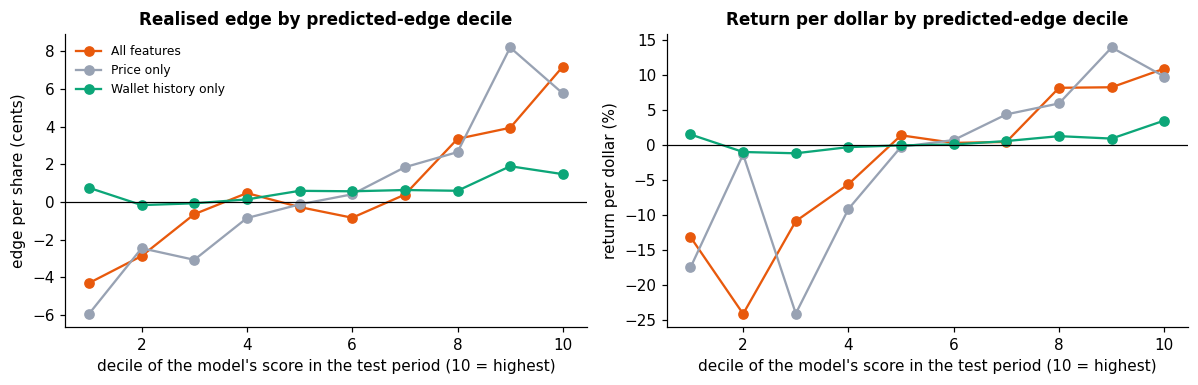

,mean predicted edge,mean realised edge,return per $,events
decile,,,,
1,-0.0824,-0.0430,-0.1311,221
2,-0.0443,-0.0286,-0.2409,243
3,-0.0243,-0.0064,-0.1085,240
4,-0.0141,0.0048,-0.0556,254
5,0.0040,-0.0026,0.0141,249
6,0.0105,-0.0083,0.0033,253
7,0.0142,0.0040,0.0047,251
8,0.0282,0.0336,0.0820,241
9,0.0487,0.0395,0.0827,227


In [26]:
if ALERTS_OK:
    def decile_table(s):
        d = test.assign(score=s); d["decile"] = pd.qcut(d["score"].rank(method="first"), 10, labels=False) + 1
        g = d.groupby("decile")
        return pd.DataFrame({"mean predicted edge": g["score"].mean(), "mean realised edge": g["edge"].mean(),
                             "return per $": d.assign(p=d["edge"] * d["size"]).groupby("decile")["p"].sum() / d.assign(k=d["entry_price"] * d["size"]).groupby("decile")["k"].sum(),
                             "events": g["event_key"].nunique()})
    dec = {k: decile_table(v["score"]) for k, v in fitted.items()}
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for name, c in (("All features", AMBER), ("Price only", GREY), ("Wallet history only", TEAL)):
        ax[0].plot(dec[name].index, dec[name]["mean realised edge"] * 100, "o-", color=c, label=name)
        ax[1].plot(dec[name].index, dec[name]["return per $"] * 100, "o-", color=c, label=name)
    for a, t, yl in ((ax[0], "Realised edge by predicted-edge decile", "edge per share (cents)"), (ax[1], "Return per dollar by predicted-edge decile", "return per dollar (%)")):
        a.axhline(0, color="k", lw=0.8); a.set(title=t, xlabel="decile of the model's score in the test period (10 = highest)", ylabel=yl)
    ax[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
    display(dec["All features"].round(4))

**Look for.** If a model works, realised edge and return **rise** from decile 1 to 10. A rising line alone is not enough: the price-only line (grey) usually rises too, because the model learns which prices tend to pay. Wallet information adds something only if the **All features** line is clearly above the **Price only** line at the top. Rank correlation with edge is not shown because it is inflated by price: edge can only range from minus the price to one minus the price.

## 14. How long before resolution do wallets trade?

**What this does.** For trades **after the cut-off**, measures how long before the market actually resolved each group traded, and draws the distributions. Groups: **all candidate trades** (the reference), **trades by the wallets flagged before the cut-off**, **past-score rule alerts** (wallet past score at least 3 with 10 or more past events), and the **model's alerts**.

**Two views.** The left chart counts *trades*. The right chart weights by *dollars*, because a few large early trades can matter more than many small late ones.

**Note.** Time to the *actual* resolution is used to describe when trades happen. It cannot be used to score a trade live, because the resolution time is unknown in advance. The model uses time to the *scheduled* end instead.

**Look for.** Whether a group trades earlier or later than everyone else. Check how **concentrated** the dollars are before reading anything into the right-hand chart: the table below the charts shows the largest wallet's share of each group's dollars and the timing **without** that wallet. Being early can mean acting before news is public, but it is also what a patient trader or a market maker looks like.

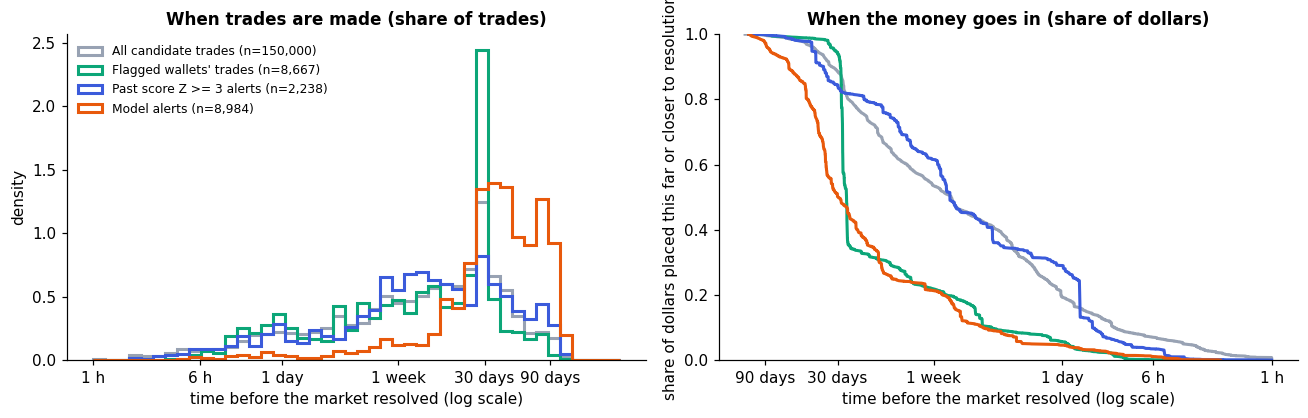

,trades,median (days before resolution),10th to 90th percentile (days),share within 1 day,share within 7 days,share 30+ days out,median day the dollars arrive (days before),largest wallet's share of dollars,"dollars arrive (days before), without the largest wallet"
All candidate trades,150000,12.440018,0.8 to 44.1,12%,38%,21%,5.37919,5%,6.160475
Flagged wallets' trades,8667,12.66507,0.8 to 34.4,12%,38%,13%,26.220533,89%,9.127604
Past score Z >= 3 alerts,2238,11.260562,0.9 to 56.4,11%,37%,24%,5.47419,31%,5.758171
Model alerts,8984,38.511059,9.9 to 87.0,2%,8%,65%,29.672234,2%,30.687639


In [27]:
if ALERTS_OK:
    flagged_codes = set(flagged_ev.index[flagged_ev.informed])
    model_main_thr = fitted["All features"]["info"]["threshold"]
    s_all = fitted["All features"]["score"]
    groups_lt = {
        "All candidate trades": test.sample(150_000, random_state=1),
        "Flagged wallets' trades": test[test.wallet.isin(flagged_codes)],
        "Past score Z >= 3 alerts": bt.dedupe_alerts(test[(test.Z_past >= 3) & (test.n_past >= 10)]),
        "Model alerts": bt.dedupe_alerts(test[s_all >= model_main_thr])}
    lt_colors = {"All candidate trades": GREY, "Flagged wallets' trades": TEAL, "Past score Z >= 3 alerts": BLUE, "Model alerts": AMBER}
    ticks, tick_lab = [1, 6, 24, 168, 720, 2160], ["1 h", "6 h", "1 day", "1 week", "30 days", "90 days"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.9)); bins = np.linspace(0, np.log10(7000), 45)
    for g, x in groups_lt.items():
        h = x["hours_to_resolve"].fillna(x["hours_to_resolve"].median()).clip(lower=1)
        ax[0].hist(np.log10(h), bins=bins, density=True, histtype="step", lw=2, color=lt_colors[g], label=f"{g} (n={len(x):,})")
        o = np.argsort(h.to_numpy()); ax[1].plot(np.log10(np.clip(h.to_numpy()[o], 1, 7000)), np.cumsum(x["usdc"].to_numpy()[o]) / x["usdc"].sum(), lw=2, color=lt_colors[g], label=g)
    for a in ax: a.set_xticks(np.log10(ticks), tick_lab); a.set_xlabel("time before the market resolved (log scale)")
    ax[0].set(title="When trades are made (share of trades)", ylabel="density"); ax[0].legend(frameon=False, fontsize=8)
    ax[1].set(title="When the money goes in (share of dollars)", ylim=(0, 1)); ax[1].invert_xaxis(); ax[1].set_ylabel("share of dollars placed this far or closer to resolution")
    plt.tight_layout(); plt.show()
    def wmedian_days(x):
        h = x["hours_to_resolve"].fillna(1e9).to_numpy(); o = np.argsort(h); c = np.cumsum(x["usdc"].to_numpy()[o]) / x["usdc"].sum()
        return h[o][np.searchsorted(c, 0.5)] / 24
    def lt_stats(x):
        h = x["hours_to_resolve"].dropna(); by_w = x.groupby("wallet")["usdc"].sum()
        return {"trades": len(x), "median (days before resolution)": h.median() / 24, "10th to 90th percentile (days)": f"{h.quantile(.1) / 24:.1f} to {h.quantile(.9) / 24:.1f}",
                "share within 1 day": f"{(h < 24).mean():.0%}", "share within 7 days": f"{(h < 168).mean():.0%}", "share 30+ days out": f"{(h > 720).mean():.0%}",
                "median day the dollars arrive (days before)": wmedian_days(x),
                "largest wallet's share of dollars": f"{by_w.max() / by_w.sum():.0%}",
                "dollars arrive (days before), without the largest wallet": wmedian_days(x[x.wallet != by_w.idxmax()])}
    display(pd.DataFrame({g: lt_stats(x) for g, x in groups_lt.items()}).T.round(1))

### Does trading earlier pay more?

Groups the **flagged wallets' and rule alerts'** trades by how long before resolution they were made, and shows the average edge per share in each bucket next to everyone else's. Buckets with few trades are noisy; the count is shown.

In [28]:
if ALERTS_OK:
    bk = [0, 24, 168, 720, 1e5]; lab = ["within 1 day", "1 to 7 days", "7 to 30 days", "30+ days"]
    def by_bucket(x):
        b = pd.cut(x["hours_to_resolve"], bk, labels=lab); g = x.groupby(b, observed=False)
        return pd.DataFrame({"trades": g.size(), "edge per share": g["edge"].mean(),
                             "return per $": x.assign(p=x["edge"] * x["size"]).groupby(b, observed=False)["p"].sum() / x.assign(k=x["entry_price"] * x["size"]).groupby(b, observed=False)["k"].sum()})
    out = pd.concat({g: by_bucket(groups_lt[g]) for g in ("All candidate trades", "Flagged wallets' trades", "Past score Z >= 3 alerts")}, axis=1)
    display(out.round(3))

All candidate trades                              \
                               trades edge per share return per $   
hours_to_resolve                                                    
within 1 day                    17593          0.006        0.005   
1 to 7 days                     38772          0.008        0.020   
7 to 30 days                    61770          0.006        0.013   
30+ days                        31865          0.003       -0.032   

                 Flagged wallets' trades                              \
                                  trades edge per share return per $   
hours_to_resolve                                                       
within 1 day                        1029          0.015        0.245   
1 to 7 days                         2236         -0.035        0.089   
7 to 30 days                        4233          0.052        0.105   
30+ days                            1169         -0.017        0.029   

                 Past score Z >= 3 alerts                              
                                   trades edge per share return per $  
hours_to_resolve                                                       
within 1 day                          255          0.028        0.120  
1 to 7 days                           566          0.029        0.052  
7 to 30 days                          879          0.010        0.050  
30+ days                              538          0.016       -0.110

## 15. If you had traded with the alerts (historical copy-trading test)

**What this does.** Replays the held-out period as if a follower had copied every alert. This is the test of whether the alerts would have made money, using only history.

**Rules of the test** (set before looking at results).
- **Stake:** a flat **$100** per alert.
- **One alert per wallet, market and side:** the first qualifying trade. Later fills by the same wallet in the same market and side are not copied again.
- **Price paid:** the price of the **next trade in that market** at or after *alert time + delay*, for the outcome the wallet holds. We have no historical order books, so this is the best available execution price. Delays: **0 minutes** (an optimistic upper bound), **5 minutes**, **1 hour**. An extra **1 cent per share** cost is tested as a second view.
- **Held to resolution.** Return = (payout - price paid) / price paid. Alerts with no later trade, or a price outside 2 to 98 cents, are skipped.
- **Uncertainty:** markets in one event are not independent, so intervals resample whole **events**. The grey band is what the **same number of randomly chosen trades** would earn, under identical rules.

**Strategies compared.** The four models' alerts; **trading with the wallets flagged before the cut-off**; and a simple **past-score rule** (wallet past score at least 3 with 10 or more past events). The price-only model is the benchmark for "no wallet information".

**Look for.** A strategy is convincing only if it is above zero **and** above the grey band, holds up at 5 minutes and 1 hour, holds up in other training cut-offs (table below the chart), **and does not depend on one wallet.** The last two table columns show how much of the profit came from the single most profitable wallet and what the return is without it. The flagged-wallet strategy rests on only about a dozen wallets, so this matters a lot.

In [29]:
if ALERTS_OK:
    tape = bt.make_tape(EVENTS_DIR / "fills_clean.parquet", test.condition_id.unique(), SPLIT)
    strat = {name: bt.dedupe_alerts(test[v["score"] >= v["info"]["threshold"]]) for name, v in fitted.items()}
    strat["Trade with flagged wallets"] = bt.dedupe_alerts(test[test.wallet.isin(flagged_codes)])
    strat["Past score Z >= 3 (10+ events)"] = bt.dedupe_alerts(test[(test.Z_past >= 3) & (test.n_past >= 10)])
    pool = bt.dedupe_alerts(test.sample(600_000, random_state=0))
    DELAYS = {"0 min (upper bound)": 0, "5 min": 300, "1 hour": 3600}
    bt_rows = []
    for dlab, d in DELAYS.items():
        for name, a in strat.items():
            sm = bt.summarize(bt.follower_results(a, tape, d, 100.0, 0.0), 500)
            rb = bt.random_benchmark(pool, tape, max(1, min(len(a), len(pool) // 2)), d, 0.0, 200) if len(a) else {}
            bt_rows.append({"delay": dlab, "strategy": name, **sm, "random_p05": rb.get("p05"), "random_p95": rb.get("p95"), "random_mean": rb.get("mean")})
    bt_res = pd.DataFrame(bt_rows)
    shown = bt_res[bt_res.delay == "5 min"].set_index("strategy")
    display(pd.DataFrame({"alerts copied": shown.alerts, "wallets": shown.wallets, "events": shown.events,
                          "return per $ staked": shown.roi.map("{:+.1%}".format), "95% interval": [f"{a:+.0%} to {b:+.0%}" for a, b in zip(shown.roi_lo, shown.roi_hi)],
                          "random trades, 5th to 95th pct": [f"{a:+.0%} to {b:+.0%}" if pd.notna(a) else "" for a, b in zip(shown.random_p05, shown.random_p95)],
                          "alerts that won": shown.win_rate.map("{:.0%}".format),
                          "most profitable wallet's share of the profit": shown.top_profit_wallet_share.map(lambda v: "" if pd.isna(v) else f"{v:.0%}"),
                          "return without that wallet": [("" if pd.isna(a) else f"{a:+.1%} ({lo:+.0%} to {hi:+.0%})") for a, lo, hi in zip(shown.roi_without_top_wallet, shown.roi_wo_lo, shown.roi_wo_hi)]}))

,alerts copied,wallets,events,return per $ staked,95% interval,"random trades, 5th to 95th pct",alerts that won,most profitable wallet's share of the profit,return without that wallet
strategy,,,,,,,,,
All features,8864,2831,193,+3.9%,-11% to +18%,-5% to +1%,59%,7%,+3.7% (-11% to +18%)
Trade features only,7893,2674,153,+6.2%,-12% to +24%,-5% to +1%,62%,2%,+6.1% (-11% to +23%)
Wallet history only,415,25,104,+14.2%,-6% to +42%,-15% to +13%,57%,71%,+5.6% (-16% to +39%)
Price only,9584,2592,159,+5.3%,-4% to +16%,-4% to +1%,63%,3%,+5.2% (-4% to +15%)
Trade with flagged wallets,941,12,201,+7.8%,-3% to +19%,-10% to +7%,51%,88%,+1.0% (-7% to +9%)
Past score Z >= 3 (10+ events),2056,49,212,+8.0%,-1% to +18%,-7% to +4%,53%,39%,+5.1% (-3% to +15%)


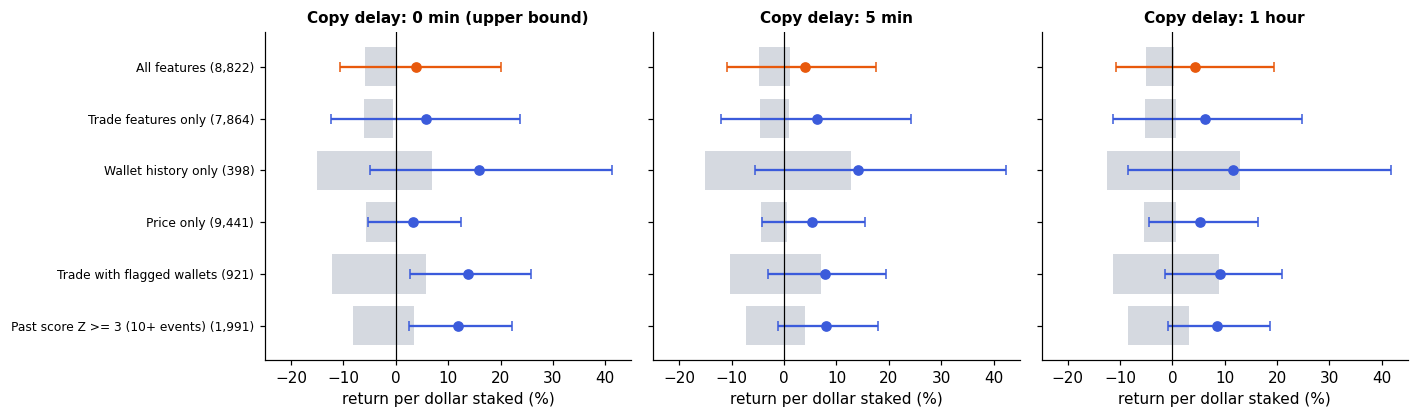

In [30]:
if ALERTS_OK:
    order = list(strat.keys()); fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), sharex=True, sharey=True)
    for a, dlab in zip(ax, DELAYS):
        d = bt_res[bt_res.delay == dlab].set_index("strategy").reindex(order); y = np.arange(len(d))[::-1]
        for yi, (nm, r) in zip(y, d.iterrows()):
            if pd.isna(r.roi): continue
            if pd.notna(r.random_p05): a.fill_betweenx([yi - 0.38, yi + 0.38], r.random_p05 * 100, r.random_p95 * 100, color=GREY, alpha=0.4, lw=0)
            a.errorbar(r.roi * 100, yi, xerr=[[(r.roi - r.roi_lo) * 100], [(r.roi_hi - r.roi) * 100]], fmt="o", color=AMBER if nm == "All features" else BLUE, capsize=3)
        a.axvline(0, color="k", lw=0.8); a.set_yticks(y, [f"{n} ({int(d.loc[n, 'alerts']):,})" for n in order], fontsize=8); a.set_xlim(-25, 45)
        a.set_title("Copy delay: " + dlab, fontsize=10); a.set_xlabel("return per dollar staked (%)")
    plt.tight_layout(); plt.show()

extra cost per share,0 cent,1 cent
strategy,,
All features,+3.9%,+1.8%
Trade features only,+6.2%,+4.3%
Wallet history only,+14.2%,+9.4%
Price only,+5.3%,+3.5%
Trade with flagged wallets,+7.8%,+3.9%
Past score Z >= 3 (10+ events),+8.0%,+4.1%


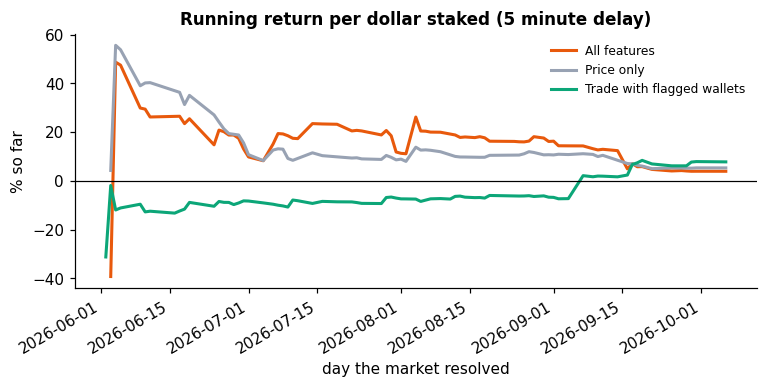

In [31]:
if ALERTS_OK:
    # one more view: 1 cent per share of extra cost, and the running return through the test period
    rows = []
    for name, a in strat.items():
        for slip in (0.0, 0.01):
            sm = bt.summarize(bt.follower_results(a, tape, 300, 100.0, slip), 300); rows.append({"strategy": name, "extra cost per share": f"{slip * 100:.0f} cent", "return per $": sm.get("roi"), "alerts": sm.get("alerts")})
    display(pd.DataFrame(rows).pivot(index="strategy", columns="extra cost per share", values="return per $").map(lambda v: "" if pd.isna(v) else f"{v:+.1%}").loc[order])
    ptime = st.period_times(mk_ev); fig, ax = plt.subplots(figsize=(8, 3.4))
    for nm, c in (("All features", AMBER), ("Price only", GREY), ("Trade with flagged wallets", TEAL)):
        cur = bt.pnl_curve(bt.follower_results(strat[nm], tape, 300, 100.0, 0.0), ptime); ax.plot(pd.to_datetime(cur["day"]), cur["cum_roi"] * 100, lw=2, color=c, label=nm)
    ax.axhline(0, color="k", lw=0.8); ax.set(title="Running return per dollar staked (5 minute delay)", ylabel="% so far", xlabel="day the market resolved"); ax.legend(frameon=False, fontsize=8); fig.autofmt_xdate(); plt.show()

### Does it hold with a different training cut-off?

The cells above use one cut-off. `python evaluate_alerts.py --cutoff 2026-05-01` and `--cutoff 2026-07-01` repeat the whole test (training included) at two more cut-offs, then `--merge` combines them. The table below reads that saved file.

In [32]:
if ALERTS_OK and (ALERTS_DIR / "backtest_table.csv").exists():
    saved = pd.read_csv(ALERTS_DIR / "backtest_table.csv")
    sel = saved[(saved.delay_s == 300) & (saved.slippage == 0) & (saved.strategy != "All candidate trades")]
    display(sel.pivot_table(index="strategy", columns="cutoff", values="roi").map(lambda v: "" if pd.isna(v) else f"{v:+.1%}").loc[[s for s in order if s in set(sel.strategy)]])
    print("Return per dollar staked, 5 minute delay, models trained on trades before each cut-off (blank = the model raised no alerts).")

cutoff,2026-05-01,2026-06-01,2026-07-01
strategy,,,
All features,-32.2%,+3.9%,-2.5%
Trade features only,-15.4%,+6.2%,-38.7%
Wallet history only,-0.7%,+14.2%,+1.3%
Price only,,+5.3%,-1.3%
Trade with flagged wallets,+6.2%,+7.8%,+19.8%
Past score Z >= 3 (10+ events),+6.9%,+8.0%,+19.0%


Return per dollar staked, 5 minute delay, models trained on trades before each cut-off (blank = the model raised no alerts).


## 16. What the alert tests do and do not show

**This is the first-version conclusion (2026 data, overlapping cut-offs). The updated conclusion is in step 21.**

**Project run (train before June 1, 2026, test after; plus May 1 and July 1).** Re-run to confirm on your machine.

**Supported.**
- **The causal setup is clean.** Every input is known at trade time, the test period is never seen in training, and a leak in an earlier version (a time-to-resolution input that used the realised resolution time for early-resolving markets) was found and removed.
- **No reliable difference in timing.** By trade count the flagged wallets trade at about the same time as everyone else (median about 12 days before resolution). Their *dollars* arrive much earlier (about 26 days against 5 days), but one wallet places about 89% of their dollars, mostly in a single event; without that wallet the figure is about 9 days. So the early-dollars pattern describes one wallet, not flagged wallets in general.
- **Simple wallet-score rules were positive in all three test windows** (about +6% to +20% per dollar at a 5 minute delay) and above the random-trade band in each. Adding 1 cent per share of cost roughly halves the return. *Caution added Nov 16:* these three windows overlap (each one's test period contains the next), so this is one stretch of time seen three ways, not three confirmations. Step 19 repeats the test on separate quarters.

**Not supported.**
- **The trained model is not better than the simple rules or the price-only benchmark.** At the main cut-off it returned a few percent with an interval spanning zero, and its return swings between roughly -30% and +4% across the three training cut-offs.
- **A reliable profit.** Most intervals include zero, and the profit is concentrated. For the flagged wallets, one wallet supplies 88% of the main window's profit; **without the single most profitable wallet the return is +1% to +12% across the three windows, and every interval includes zero.** The past-score rule is broader (about 50 wallets) but loses about half of its return the same way (+5% to +14% without its top wallet, intervals still include zero). The flagged-wallet running return was also below zero until a few large late events resolved. Treat the simple rules as suggestive at best.
- **Private information.** Being early and being right is also what a patient trader or a market maker looks like.

**How to word it.** "A back-test of copying alerts, using only data available at the time, returned X% per dollar (95% interval Y to Z) over N alerts." Never "insiders", and never advice to trade.

**Running the live alerts.**
```bash
python evaluate_alerts.py --live-model    # fit on all resolved history, save the model and a wallet snapshot (about 15 s)
python live_alerts.py                     # scores new trades in the largest open markets -> site/data/live_alerts.json
python build_dashboard.py --data data_events/live --results results_v2    # rebuild the Alerts page data
```
Live alerts are a demonstration: the model was validated on history only, and returns on open trades appear only after the market resolves.

# Part B: the full history (added November 16, 2026)

Steps 1 to 16 used the first data set: 1,610 markets that resolved Jan to Sep 2026. Part B uses everything downloaded since: all of 2025 and Oct to Nov 2026. It **supersedes the alert conclusions of steps 13 to 16**.

Part B reads the saved result files (it does not redo the heavy computing), so it runs in seconds. To regenerate those files see `handoff.md`, sections 16 to 20.

## 17. More data: 3,713 markets, Jan 2025 to Nov 2026

**What this does.** Shows what was added and checks that the combined data still passes the basic accounting test: every trade has a buyer and a seller, so **total profit across all wallets should be about $0**.

**Why more data.** Wallet skill is hard to separate from luck with few events per wallet; more events per wallet and more wallets give the flagging test more power and give the alert tests more independent periods. The newest window (Oct 1 to Nov 14, 2026) was set aside and **not used for any decision**, so it can serve as a final, one-shot test (step 20).

In [33]:
R3, R4 = Path("results_v3"), Path("results_v4")
FULL_DIR = Path("data_events_full/live")
FULL_FILES = [Path("data_events_full_markets.parquet"), R3 / "events_table_events.parquet", R3 / "events_table_placebo.parquet",
              R3 / "alerts_windows" / "pooled_table.csv", R3 / "alerts_windows" / "backtest_table.csv",
              R3 / "alerts_fresh" / "fresh_backtest.csv", FULL_DIR / "milestone1_report.json", R4 / "validation_report.json"]
FULL_OK = (not SIM) and all(p.exists() for p in FULL_FILES)
if not FULL_OK:
    print("Part B needs the saved full-history results (see handoff.md sections 16 to 20). Skipping it.")
else:
    mkt_all = pd.read_parquet("data_events_full_markets.parquet")
    label = {"data_events_2025/live": "2025 (Jan to Dec)", "data_events/live": "2026, Jan to Sep (steps 1 to 16)", "data_events_fresh/live": "2026, Oct to Nov (kept fresh)"}
    t = mkt_all.groupby("source_run").agg(markets=("condition_id", "size"), volume_billion=("volume", lambda v: v.sum() / 1e9),
                                          first_resolved=("end_time", "min"), last_resolved=("end_time", "max"))
    t.index = [label[i] for i in t.index]; t["first_resolved"] = t["first_resolved"].dt.date; t["last_resolved"] = t["last_resolved"].dt.date
    display(t.round(2))
    rep = json.load(open(FULL_DIR / "milestone1_report.json"))
    print(f"Combined: {rep['cleaning']['markets']:,} markets, {rep['cleaning']['clean_rows']:,} trades, {rep['cleaning']['wallets']:,} wallets, "
          f"${rep['pnl_sanity']['sum_volume'] / 1e9:.2f} billion traded.")
    print(f"Accounting check: total profit across all wallets = ${rep['pnl_sanity']['sum_pnl_all_wallets']:,.0f} (should be about $0). "
          "Trades that appear to create or merge shares are rare: "
          f"{rep['pnl_sanity']['share_wallet_markets_with_splits']:.1%} of wallet-markets.")

,markets,volume_billion,first_resolved,last_resolved
"2026, Jan to Sep (steps 1 to 16)",1610,3.84,2026-01-01,2026-09-30
2025 (Jan to Dec),1508,3.93,2025-01-10,2025-12-31
"2026, Oct to Nov (kept fresh)",595,0.87,2026-10-01,2026-11-05


Combined: 3,713 markets, 35,583,634 trades, 1,058,910 wallets, $5.69 billion traded.
Accounting check: total profit across all wallets = $-465 (should be about $0). Trades that appear to create or merge shares are rare: 1.6% of wallet-markets.


## 18. Re-flagging on the full history

**What happened.** The flagging test of step 4 was run on all 3,713 markets. Of 17,254 wallets with at least 10 events it flagged only **23** (0.13%), barely more than the 19 flagged of 4,009 wallets in the smaller data set, although there are more than four times as many wallets. Something about the test was too strict.

**Why.** The test compares each wallet's score `Z` with what pure luck would produce, which should have a spread of 1. Step 4 never allows the spread to be *below* 1. On the real data the spread of `Z` across ordinary wallets is only about **0.6** (the formula for how much luck can move a result is deliberately cautious: it adds up the outcomes of one event as if they moved together, though they partly offset). With the spread forced up to 1, almost no one clears the bar.

**The fix, in words.** Measure the spread (and the centre) of `Z` from the *bulk* of wallets, which is mostly ordinary luck, and judge each wallet against that. This is a standard idea (an *empirical null*). We compare three rules:
- **R0**: the original (spread at least 1, centre at 0).
- **R1**: spread measured from the data, centre at 0.
- **R2**: spread and centre both measured from the data. **This is the candidate for the new default.**

**The proof has to come from outside the flagging data.** Wallets are flagged on events resolved before the cut-off and judged on events after it, and compared with similar-sized wallets (same trading volume and number of events). The **placebo** (crypto up/down) and a **no-skill simulation** check for false flags.

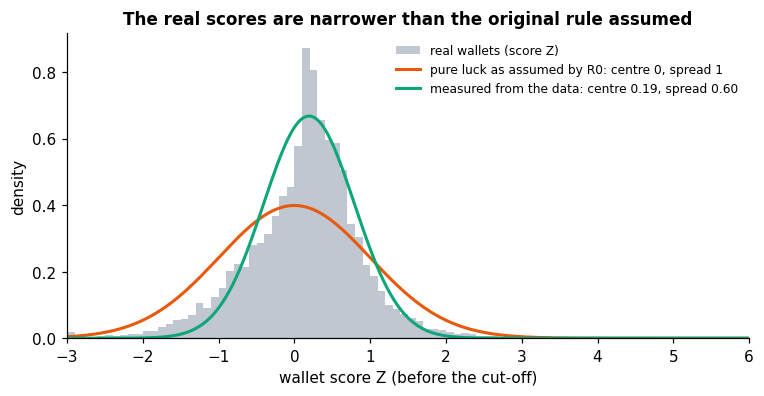

Spread measured from 17,254 wallets: 0.60 (the original rule used 1.00). Centre: +0.19 (the original used 0).


In [34]:
if FULL_OK:
    evf = pd.read_parquet(R3 / "events_table_events.parquet")
    evpf = pd.read_parquet(R3 / "events_table_placebo.parquet")
    sfull = st.wallet_stats(evf[evf.period_time < split_ts], 10)
    zf = sfull.loc[sfull.eligible, "Z"].dropna().to_numpy()
    sig, mid = st.empirical_sigma(zf, floor=0.0), float(np.median(zf))
    fig, ax = plt.subplots(figsize=(8, 3.6)); xs = np.linspace(-3, 6, 400)
    ax.hist(np.clip(zf, -3, 6), bins=90, density=True, color=GREY, alpha=0.6, label="real wallets (score Z)")
    ax.plot(xs, stats.norm.pdf(xs, 0, 1), color=AMBER, lw=2, label="pure luck as assumed by R0: centre 0, spread 1")
    ax.plot(xs, stats.norm.pdf(xs, mid, sig), color=TEAL, lw=2, label=f"measured from the data: centre {mid:.2f}, spread {sig:.2f}")
    ax.set(title="The real scores are narrower than the original rule assumed", xlabel="wallet score Z (before the cut-off)", ylabel="density", xlim=(-3, 6)); ax.legend(frameon=False, fontsize=8)
    plt.show()
    print(f"Spread measured from {len(zf):,} wallets: {sig:.2f} (the original rule used 1.00). Centre: {mid:+.2f} (the original used 0).")

In [35]:
if FULL_OK:
    RULES = {"R0: original": dict(sigma_floor=1.0, center=False), "R1: spread from data": dict(sigma_floor=0.0, center=False),
             "R2: spread and centre from data": dict(sigma_floor=0.0, center=True)}
    rows = []
    for nm, kw in RULES.items():
        for samp, e in (("main sample", evf), ("placebo", evpf)):
            s_, r_ = st.run_split(e, SPLIT, min_events=10, q=Q, method="BH", **kw)
            c_, x_ = r_["calibration"], r_["evaluation"]; ci = x_.get("mean_z_diff_vs_matched_ci95") or [np.nan, np.nan]
            rows.append({"rule": nm, "sample": samp, "eligible wallets": c_["eligible_wallets"], "flagged": c_["flagged"], "share flagged": f"{c_['flag_rate']:.2%}",
                         "flagged wallets scored later": x_.get("n_informed_with_eval"),
                         "later score vs matched wallets": f"{x_.get('mean_z_diff_vs_matched', np.nan):+.2f} ({ci[0]:+.2f} to {ci[1]:+.2f})",
                         "profit per $, flagged vs others": f"{x_.get('pooled_profit_per_dollar_informed', np.nan):.1%} vs {x_.get('pooled_profit_per_dollar_rest', np.nan):.1%}"})
    display(pd.DataFrame(rows).set_index(["rule", "sample"]))

eligible wallets  flagged  \
rule                            sample                                   
R0: original                    main sample             17254       23   
                                placebo                  3944       21   
R1: spread from data            main sample             17254      345   
                                placebo                  3944       37   
R2: spread and centre from data main sample             17254      207   
                                placebo                  3944       22   

                                            share flagged  \
rule                            sample                      
R0: original                    main sample         0.13%   
                                placebo             0.53%   
R1: spread from data            main sample         2.00%   
                                placebo             0.94%   
R2: spread and centre from data main sample         1.20%   
                                placebo             0.56%   

                                             flagged wallets scored later  \
rule                            sample                                      
R0: original                    main sample                            22   
                                placebo                                 8   
R1: spread from data            main sample                           266   
                                placebo                                15   
R2: spread and centre from data main sample                           170   
                                placebo                                 9   

                                            later score vs matched wallets  \
rule                            sample                                       
R0: original                    main sample         +0.28 (+0.09 to +0.48)   
                                placebo             +0.46 (-0.10 to +1.07)   
R1: spread from data            main sample         +0.15 (+0.07 to +0.23)   
                                placebo             +0.34 (-0.06 to +0.77)   
R2: spread and centre from data main sample         +0.23 (+0.13 to +0.34)   
                                placebo             +0.42 (-0.06 to +0.95)   

                                            profit per $, flagged vs others  
rule                            sample                                       
R0: original                    main sample                    9.0% vs 1.8%  
                                placebo                       12.7% vs 1.1%  
R1: spread from data            main sample                    5.7% vs 1.5%  
                                placebo                        8.2% vs 1.1%  
R2: spread and centre from data main sample                    6.7% vs 1.5%  
                                placebo                       12.7% vs 1.1%

**Look for.** (1) On the main sample the less strict rules flag far more wallets and those wallets **still beat matched wallets afterwards** (intervals above zero). (2) The placebo's flag rate should stay low and, ideally, **below** the main sample's: under R0 the placebo flagged *more* wallets than the main sample (a bad sign for the method); under R2 it flags about half as many. (3) The placebo's flagged wallets still show some persistence, so persistence by itself is **not** proof of private information.

In [36]:
if FULL_OK:
    # do the EXTRA wallets that only R2 flags also beat matched wallets? (the cleanest test that the extra flags are real)
    rows = []
    for sp in ("2026-05-01", "2026-06-01", "2026-07-01"):
        spt = pd.Timestamp(sp, tz="UTC"); fm, evl = evf[evf.period_time < spt], evf[evf.period_time >= spt]
        s0 = st.flag_wallets(st.wallet_stats(fm, 10), **RULES["R0: original"]); s2 = st.flag_wallets(st.wallet_stats(fm, 10), **RULES["R2: spread and centre from data"])
        extra = s2["informed"] & ~s0["informed"]; tt = s2.copy(); tt["informed"] = extra; tt.loc[s0["informed"], "eligible"] = False
        x_ = st.evaluate(tt, evl); ci = x_["mean_z_diff_vs_matched_ci95"]
        rows.append({"cut-off": sp, "extra wallets (R2 only)": int(extra.sum()), "scored later": x_["n_informed_with_eval"],
                     "later score vs matched wallets": f"{x_['mean_z_diff_vs_matched']:+.2f} ({ci[0]:+.2f} to {ci[1]:+.2f})",
                     "profit per $, extra wallets vs others": f"{x_['pooled_profit_per_dollar_informed']:.1%} vs {x_['pooled_profit_per_dollar_rest']:.1%}"})
    display(pd.DataFrame(rows).set_index("cut-off"))
    print("The three cut-offs overlap in time, so this is encouraging, not three independent confirmations.")

,extra wallets (R2 only),scored later,later score vs matched wallets,"profit per $, extra wallets vs others"
cut-off,,,,
2026-05-01,179,143,+0.15 (+0.05 to +0.26),6.8% vs 1.3%
2026-06-01,184,148,+0.22 (+0.12 to +0.34),6.4% vs 1.5%
2026-07-01,190,152,+0.19 (+0.09 to +0.30),7.0% vs 1.6%


The three cut-offs overlap in time, so this is encouraging, not three independent confirmations.


In [37]:
if FULL_OK:
    # false flags and recovery in a world where we KNOW who is skilled (simulation: 3 random worlds per rule)
    rows = []
    for nm, kw in RULES.items():
        sv = r2.synthetic_validation(n_seeds=3, **kw)
        n_ = pd.DataFrame([x for x in sv["noise_only"] if x["method"] == "BH"]); p_ = pd.DataFrame([x for x in sv["planted"] if x["method"] == "BH"])
        rows.append({"rule": nm, "wallets flagged when nobody is skilled": int(n_["flagged"].sum()),
                     "skilled wallets found (recall)": f"{p_['recall'].mean():.0%}", "flagged wallets that really are skilled (precision)": f"{p_['precision'].mean():.0%}"})
    display(pd.DataFrame(rows).set_index("rule"))

,wallets flagged when nobody is skilled,skilled wallets found (recall),flagged wallets that really are skilled (precision)
rule,,,
R0: original,0,42%,100%
R1: spread from data,0,81%,98%
R2: spread and centre from data,0,83%,96%


In [38]:
if FULL_OK:
    # who is in the flagged lists? (concentration and wallet type)
    rows = []
    for nm, d in (("R0 original", R3), ("R2 less conservative", R4)):
        w = pd.read_csv(d / "likely_informed_wallets.csv"); p_ = w["profit"]
        rows.append({"rule": nm, "flagged wallets": len(w), "top wallet's share of the group's profit": f"{p_.max() / p_.sum():.0%}",
                     "top 5 wallets' share": f"{p_.nlargest(5).sum() / p_.sum():.0%}", "traded under $1,000 in total": int((w.volume < 1000).sum()),
                     "earn under 1% per dollar (looks like a bot or market maker)": int((w.profit_per_dollar < 0.01).sum()), "median events": int(w.n_events.median())})
    display(pd.DataFrame(rows).set_index("rule"))

,flagged wallets,top wallet's share of the group's profit,top 5 wallets' share,"traded under $1,000 in total",earn under 1% per dollar (looks like a bot or market maker),median events
rule,,,,,,
R0 original,23,72%,87%,2,4,73
R2 less conservative,207,13%,44%,30,34,38


**How to read the last two tables.** In the simulation, no rule flags anyone when nobody is skilled, and R2 finds about 80% of the skilled wallets at about 96% precision (R0 finds fewer than half). On the real data the original list was dominated by one account; the new list is much broader but contains many tiny or high-frequency accounts. **Call them "likely informed" candidates, never proven insiders.** The choice of R2 was made after seeing later-period results, so treat it as promising until a clean new period confirms it.

## 19. Forward test of the alerts on five separate quarters

**Why redo the test.** In step 15 the three cut-offs overlapped (the test period of May 1 contains those of June 1 and July 1), so "positive in all three" was one stretch of time seen three ways. Here each quarter is its own test: the model is trained **only on trades before the quarter**, then tested **only on trades made inside it**, in events that **resolved inside it**. Five quarters, Jul 2025 to Sep 2026. Everything else follows step 15 ($100 per alert, price 5 minutes after the alert, held to resolution, intervals resample whole events).

**New comparisons.**
- **Crowd flow (no wallet skill):** a model that only sees price and how much money from *any* wallet has recently gone onto the same side. If "good wallets agree" is real, it must beat this one.
- **Agreement:** how much money *other wallets with a strong record* have already put on the same side of the same market.
- **Simple rule (no model):** copy wallets with past score Z >= 3 over at least 10 events. This rule was fixed in step 15, before these quarters were looked at.

**Look for.** Whether a strategy's interval **pooled over all quarters** is above zero and the result is positive in most quarters. A strategy that is great in one quarter and terrible in another is not reliable.

In [39]:
if FULL_OK:
    NICE = {"All features": "Old alert model (all features)", "Price only": "Price only", "Crowd flow (no wallet skill)": "Crowd flow only (no wallet skill)",
            "Trade + agreement (no own history)": "Price/trade + agreement", "All + agreement": "Model + agreement",
            "All + agreement + flow": "Model + agreement + crowd flow", "Trade with flagged wallets": "Trade with flagged wallets (original rule)",
            "Past score Z >= 3 (10+ events)": "SIMPLE RULE: past score Z>=3, 10+ events", "All candidate trades": "All candidate trades (reference)"}
    pooled = pd.read_csv(R3 / "alerts_windows" / "pooled_table.csv"); winb = pd.read_csv(R3 / "alerts_windows" / "backtest_table.csv")
    p5 = pooled[pooled.delay == "5 min"].set_index("strategy").reindex([k for k in NICE if k in set(pooled.strategy)])
    display(pd.DataFrame({"alerts": p5.alerts.astype(int), "events": p5.events.astype(int), "return per $ (pooled)": p5.roi.map("{:+.1%}".format),
                          "95% interval": [f"{a:+.0%} to {b:+.0%}" for a, b in zip(p5.roi_lo, p5.roi_hi)],
                          "quarters positive": [f"{int(a)} of {int(b)}" for a, b in zip(p5.windows_positive, p5.windows)],
                          "top wallet's share of profit": p5.top_profit_wallet_share.map(lambda v: "" if pd.isna(v) else f"{v:.0%}")}).rename(index=NICE))
    print("Return per dollar staked over all five quarters pooled, 5 minute delay. 'Alerts' counts one copied trade per wallet, market and side.")

,alerts,events,return per $ (pooled),95% interval,quarters positive,top wallet's share of profit
strategy,,,,,,
Old alert model (all features),4383,223,-20.7%,-42% to +1%,3 of 5,
Price only,779,39,-16.5%,-50% to +33%,0 of 1,
Crowd flow only (no wallet skill),13413,255,-2.3%,-26% to +22%,2 of 5,
Price/trade + agreement,12439,172,+8.9%,-16% to +33%,2 of 4,1%
Model + agreement,11667,166,+9.1%,-20% to +39%,2 of 4,1%
Model + agreement + crowd flow,11738,170,+12.9%,-15% to +47%,3 of 5,1%
Trade with flagged wallets (original rule),3147,588,+7.8%,-0% to +18%,4 of 5,56%
"SIMPLE RULE: past score Z>=3, 10+ events",7023,643,+8.1%,+2% to +15%,3 of 5,24%
All candidate trades (reference),314737,695,-3.7%,-9% to +2%,1 of 5,


Return per dollar staked over all five quarters pooled, 5 minute delay. 'Alerts' counts one copied trade per wallet, market and side.


,2025-07 to 2025-10,2025-10 to 2026-01,2026-01 to 2026-04,2026-04 to 2026-07,2026-07 to 2026-10
strategy,,,,,
Old alert model (all features),-4%,+4%,+166%,+4%,-46%
Price only,-17%,no alerts,no alerts,no alerts,no alerts
Crowd flow only (no wallet skill),-93%,-31%,+138%,+28%,-2%
Price/trade + agreement,-100%,-67%,no alerts,+21%,+9%
Model + agreement,-100%,-41%,no alerts,+23%,+7%
Model + agreement + crowd flow,-100%,-19%,+55%,+31%,+3%
Trade with flagged wallets (original rule),-5%,+15%,+15%,+1%,+7%
"SIMPLE RULE: past score Z>=3, 10+ events",-11%,+15%,+18%,-1%,+15%
All candidate trades (reference),-16%,-7%,-1%,+1%,-3%


,2025-07 to 2025-10,2025-10 to 2026-01,2026-01 to 2026-04,2026-04 to 2026-07,2026-07 to 2026-10
number of alerts per quarter,,,,,
Old alert model (all features),173,1668,23,305,2214
Price only,779,0,0,0,0
Crowd flow only (no wallet skill),45,4087,15,3932,5334
Price/trade + agreement,611,238,0,6831,4759
Model + agreement,559,327,0,6193,4588
Model + agreement + crowd flow,599,69,16,6398,4656
Trade with flagged wallets (original rule),339,990,413,812,593
"SIMPLE RULE: past score Z>=3, 10+ events",455,1173,1311,2573,1511
All candidate trades (reference),31422,61551,53575,83367,84822


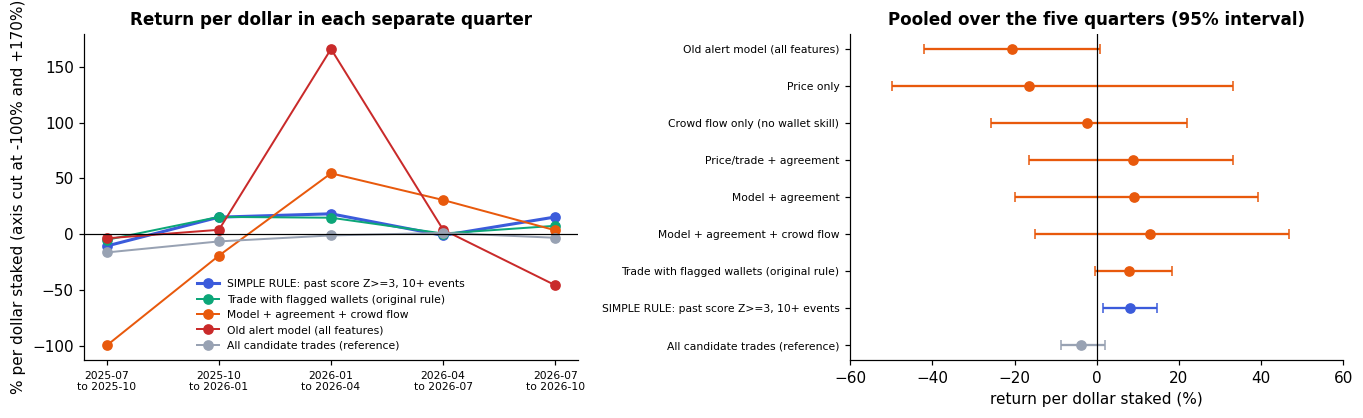

In [40]:
if FULL_OK:
    w5 = winb[(winb.delay_s == 300) & (winb.slippage == 0) & winb.strategy.isin(NICE)]
    pv = w5.pivot_table(index="strategy", columns="cutoff", values="roi").reindex([k for k in NICE if k in set(w5.strategy)])
    pv.columns = [c.split("_")[0][:7] + " to " + c.split("_")[1][:7] for c in pv.columns]
    display(pv.rename(index=NICE).map(lambda v: "no alerts" if pd.isna(v) else f"{v:+.0%}"))
    cnt = w5.pivot_table(index="strategy", columns="cutoff", values="alerts").reindex(pv.index).fillna(0).astype(int); cnt.columns = pv.columns
    display(cnt.rename(index=NICE).rename_axis("number of alerts per quarter"))
    keys = ["Past score Z >= 3 (10+ events)", "Trade with flagged wallets", "All + agreement + flow", "All features", "All candidate trades"]
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
    cols = {"Past score Z >= 3 (10+ events)": BLUE, "Trade with flagged wallets": TEAL, "All + agreement + flow": AMBER, "All features": "#c92a2a", "All candidate trades": GREY}
    for k in keys:
        if k in pv.index: ax[0].plot(range(pv.shape[1]), (pv.loc[k].clip(-1, 1.7) * 100).to_numpy(), "o-", color=cols[k], label=NICE[k], lw=2 if k.startswith("Past") else 1.3)
    ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xticks(range(pv.shape[1]), [c.replace(" to ", "\nto ") for c in pv.columns], fontsize=7)
    ax[0].set(title="Return per dollar in each separate quarter", ylabel="% per dollar staked (axis cut at -100% and +170%)"); ax[0].legend(frameon=False, fontsize=7)
    y = np.arange(len(p5))[::-1]
    for yi, (nm, r) in zip(y, p5.iterrows()):
        ax[1].errorbar(r.roi * 100, yi, xerr=[[(r.roi - r.roi_lo) * 100], [(r.roi_hi - r.roi) * 100]], fmt="o", capsize=3, color=BLUE if nm.startswith("Past") else (GREY if nm.startswith("All cand") else AMBER))
    ax[1].axvline(0, color="k", lw=0.8); ax[1].set_yticks(y, [NICE[n] for n in p5.index], fontsize=7); ax[1].set_xlim(-60, 60)
    ax[1].set(title="Pooled over the five quarters (95% interval)", xlabel="return per dollar staked (%)")
    plt.tight_layout(); plt.show()

**What this shows.**
- **The old model loses money out of sample** (pooled about -21%), and the machine-learning versions swing wildly from quarter to quarter (one quarter loses nearly everything on a handful of events, another gains over 50%). The number of alerts they raise ranges from 0 to over 6,000 a quarter, because the alert threshold set on past data does not carry over to a new period. This is a **negative result and should be reported as one**.
- **"Agreement" is not established.** The agreement versions are positive pooled (+9% to +13%) but the interval (about -15% to +47%) spans zero, and the gain comes mostly from one quarter (Apr to Jun 2026). It does beat the crowd-flow-only model by roughly 10 points, which hints that who is trading matters, but the data cannot confirm it.
- **The simple rule is the only strategy whose pooled interval is above zero:** about +8% per dollar (interval about +2% to +15%), roughly 12 points better than copying a random trade (about -4%), positive in 3 of 5 quarters.
- **Most of this is still before real-world costs.** It is a historical replay with no limit on how much could be bought at the price, and the earlier 1-cent-per-share test roughly halves the simple rule's return.

## 20. One-shot test of the frozen rule on the fresh Oct-Nov 2026 window

**What this does.** The newest window (Oct 1 to Nov 14, 2026; 256 events) was never used for any decision. We freeze **one primary rule** (the simple rule of step 19, exactly as defined before any of these tests) and run it **once**. Two flagged-wallet strategies are shown as secondary. Nothing is trained, so nothing can leak.

**Look for.** The point estimate should be close to the earlier quarters' result (about +8%). The interval is likely to be wide because it is one short window. Compare with the random-trade reference **in the same window**: it can be positive too.

,alerts,wallets,events,return per $,95% interval,top wallet's share of profit,"random trades, same rules"
strategy,,,,,,,
"PRIMARY: simple rule, past score Z>=3, 10+ events",3507,60,238,+8.4%,-1% to +18%,17%,+4.0%
"Secondary: flagged wallets, original rule",2346,21,238,+10.4%,-0% to +21%,21%,+4.0%
"Secondary: flagged wallets, less conservative rule",5831,108,241,+8.5%,-2% to +21%,10%,+4.0%
All candidate trades,98842,9968,252,+4.1%,-6% to +15%,3%,


extra cost,1 cent per share,none
primary rule: delay vs extra cost,,
0 min (upper bound),,+9.5%
5 min,+4.8%,+8.4%
1 hour,+2.7%,+6.2%


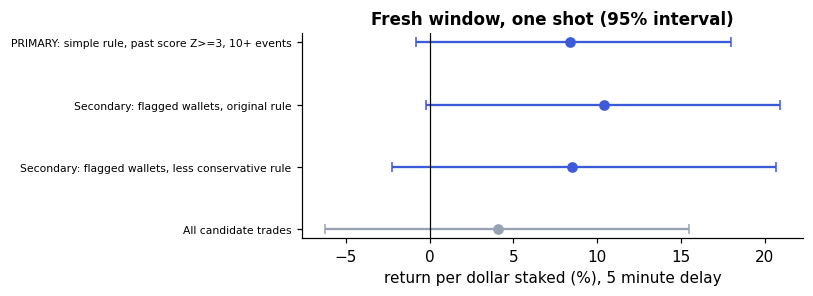

In [41]:
if FULL_OK:
    fr = pd.read_csv(R3 / "alerts_fresh" / "fresh_backtest.csv")
    nm_f = lambda s: s.replace("PRIMARY: past score Z >= 3 (10+ events)", "PRIMARY: simple rule, past score Z>=3, 10+ events").replace("Secondary: flagged wallets, original rule", "Secondary: flagged wallets, original rule").replace("Secondary: flagged wallets, less conservative rule", "Secondary: flagged wallets, less conservative rule")
    f5 = fr[(fr.slippage == 0) & (fr.delay == "5 min")].copy(); f5["strategy"] = f5.strategy.map(nm_f)
    fshow = f5.set_index("strategy")
    display(pd.DataFrame({"alerts": fshow.alerts.astype(int), "wallets": fshow.wallets.astype(int), "events": fshow.events.astype(int),
                          "return per $": fshow.roi.map("{:+.1%}".format), "95% interval": [f"{a:+.0%} to {b:+.0%}" for a, b in zip(fshow.roi_lo, fshow.roi_hi)],
                          "top wallet's share of profit": fshow.top_profit_wallet_share.map(lambda v: "" if pd.isna(v) else f"{v:.0%}"),
                          "random trades, same rules": fshow.random_mean.map(lambda v: "" if pd.isna(v) else f"{v:+.1%}")}))
    prim = fr[fr.strategy.str.startswith("PRIMARY")].copy(); prim["extra cost"] = np.where(prim.slippage > 0, "1 cent per share", "none")
    display(prim.pivot_table(index="delay", columns="extra cost", values="roi").reindex(["0 min (upper bound)", "5 min", "1 hour"]).map(lambda v: "" if pd.isna(v) else f"{v:+.1%}").rename_axis("primary rule: delay vs extra cost"))
    fig, ax = plt.subplots(figsize=(7.5, 2.8)); y = np.arange(len(f5))[::-1]
    for yi, (_, r) in zip(y, f5.iterrows()):
        ax.errorbar(r.roi * 100, yi, xerr=[[(r.roi - r.roi_lo) * 100], [(r.roi_hi - r.roi) * 100]], fmt="o", capsize=3, color=GREY if r.strategy.startswith("All") else BLUE)
    ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y, [s[:52] for s in f5.strategy], fontsize=7); ax.set_xlabel("return per dollar staked (%), 5 minute delay"); ax.set_title("Fresh window, one shot (95% interval)")
    plt.tight_layout(); plt.show()

**Reading.** The primary rule earned about **+8%** per dollar at a 5-minute delay, the same size as the earlier quarters, so the result did not fall apart on unseen data. But the interval **includes zero**, and random trades also earned about +4% in this window, so the edge over random is only about 4 points. With 1 cent per share of extra cost the result drops to about +5% against about +1% for random trades. **A modest edge that is consistent in size but not statistically established.**

## 21. When do likely-informed wallets trade?

**The question.** At the beginning of a market's life, right before the news, when the price moves, or some other time?

**How it is measured.** Take the wallets flagged **before** the cut-off (the less conservative rule of step 18; 207 wallets) and look only at events that resolved **after** it, so the wallets were never picked for the timing being measured. Compare them with the other experienced wallets (17,000) and with all traders. Four "clocks":
1. **Share of the market's life elapsed** (0% = opened, 100% = resolved).
2. **Time before the market resolved.**
3. **Time relative to the market's biggest price shift in one hour** (at least 15 cents; the revelation proxy; 528 markets).
4. **Minutes around the sharpest 10-minute price jump** (at least 10 cents; 631 markets). This is the closest we get to "right before the news hit".

Each wallet counts once in the shares, so a few large wallets cannot dominate, and intervals resample wallets. The numbers come from saved files (`python timing_analysis.py process`, then `report`).

**Look for.** Where the orange bars (flagged wallets) stand out from the blue ones (other experienced wallets), and whether the money in those moments is **on the side the price then moved to** (above 50%) and **profitable**.

In [42]:
TIMING = R4 / "timing"
TIMING_OK = FULL_OK and (TIMING / "timing_clock_shares.csv").exists() and (TIMING / "figures" / "timing_clocks.png").exists()
if not TIMING_OK:
    print("Step 21 needs results_v4/timing (run: python timing_analysis.py process ; python timing_analysis.py report). Skipping it.")
else:
    from IPython.display import Image
    tsum = json.load(open(TIMING / "timing_summary.json"))
    print(f"Wallets: {tsum['wallets']}.  Markets: {tsum['markets']:,} (hourly shift in {tsum['markets_with_shift']}, sharp 10-minute jump in {tsum['markets_with_sharp_jump']}).")
    cs = pd.read_csv(TIMING / "timing_clock_shares.csv")
    FG, OG = "Flagged wallets (less conservative rule)", "Other experienced wallets"
    def clock_table(clock, buckets):
        d = cs[(cs.clock == clock) & cs.bucket.isin(buckets)]
        f = d[d.group == FG].set_index("bucket").reindex(buckets); o = d[d.group == OG].set_index("bucket").reindex(buckets); a_ = d[d.group == "All traders"].set_index("bucket").reindex(buckets)
        return pd.DataFrame({"flagged wallets": [f"{v:.1%} ({lo:.1%} to {hi:.1%})" for v, lo, hi in zip(f.wallet_equal_share, f.wallet_equal_lo, f.wallet_equal_hi)],
                             "other experienced wallets": o.wallet_equal_share.map("{:.1%}".format).to_numpy(), "all traders (dollars)": a_.pooled_dollar_share.map("{:.1%}".format).to_numpy()}, index=buckets)
    print("Share of each group's dollars (each wallet counts once; interval = flagged wallets resampled)")
    display(clock_table("Share of the market's life elapsed", ["0-10%", "10-20%", "80-90%", "90-100%"]).rename_axis("share of the market's life elapsed"))
    display(clock_table("Time before the market resolved", ["under 1 h", "1-6 h", "6-24 h", "7-30 days", "90+ days"]).rename_axis("time before resolution"))
    display(clock_table("Minutes around the sharpest 10-minute jump", ["10-30 min before", "the 10 minutes before", "the 10 minutes of the jump", "10-30 min after", "30-60 min after"]).rename_axis("time around the sharpest jump"))

Wallets: {'Experienced (10+ events before the cut-off)': 17254, 'Flagged (less conservative rule)': 207, 'Flagged (original rule)': 23}.  Markets: 1,309 (hourly shift in 528, sharp 10-minute jump in 631).
Share of each group's dollars (each wallet counts once; interval = flagged wallets resampled)


,flagged wallets,other experienced wallets,all traders (dollars)
share of the market's life elapsed,,,
0-10%,5.5% (3.8% to 7.5%),3.7%,0.8%
10-20%,5.5% (3.8% to 7.7%),4.2%,1.1%
80-90%,10.4% (8.5% to 12.4%),12.2%,10.3%
90-100%,33.6% (28.8% to 38.6%),36.5%,51.4%


,flagged wallets,other experienced wallets,all traders (dollars)
time before resolution,,,
under 1 h,0.2% (0.0% to 0.5%),0.3%,0.8%
1-6 h,5.9% (4.3% to 7.7%),4.2%,8.4%
6-24 h,7.9% (5.9% to 10.2%),7.8%,10.6%
7-30 days,20.1% (17.3% to 23.1%),23.8%,19.9%
90+ days,29.6% (23.7% to 35.6%),24.6%,16.4%


,flagged wallets,other experienced wallets,all traders (dollars)
time around the sharpest jump,,,
10-30 min before,1.5% (0.9% to 2.2%),0.5%,0.4%
the 10 minutes before,2.0% (1.0% to 3.0%),0.6%,0.3%
the 10 minutes of the jump,3.7% (2.1% to 5.8%),1.2%,1.7%
10-30 min after,1.5% (1.1% to 2.0%),0.8%,1.0%
30-60 min after,2.0% (1.1% to 3.1%),1.0%,1.2%


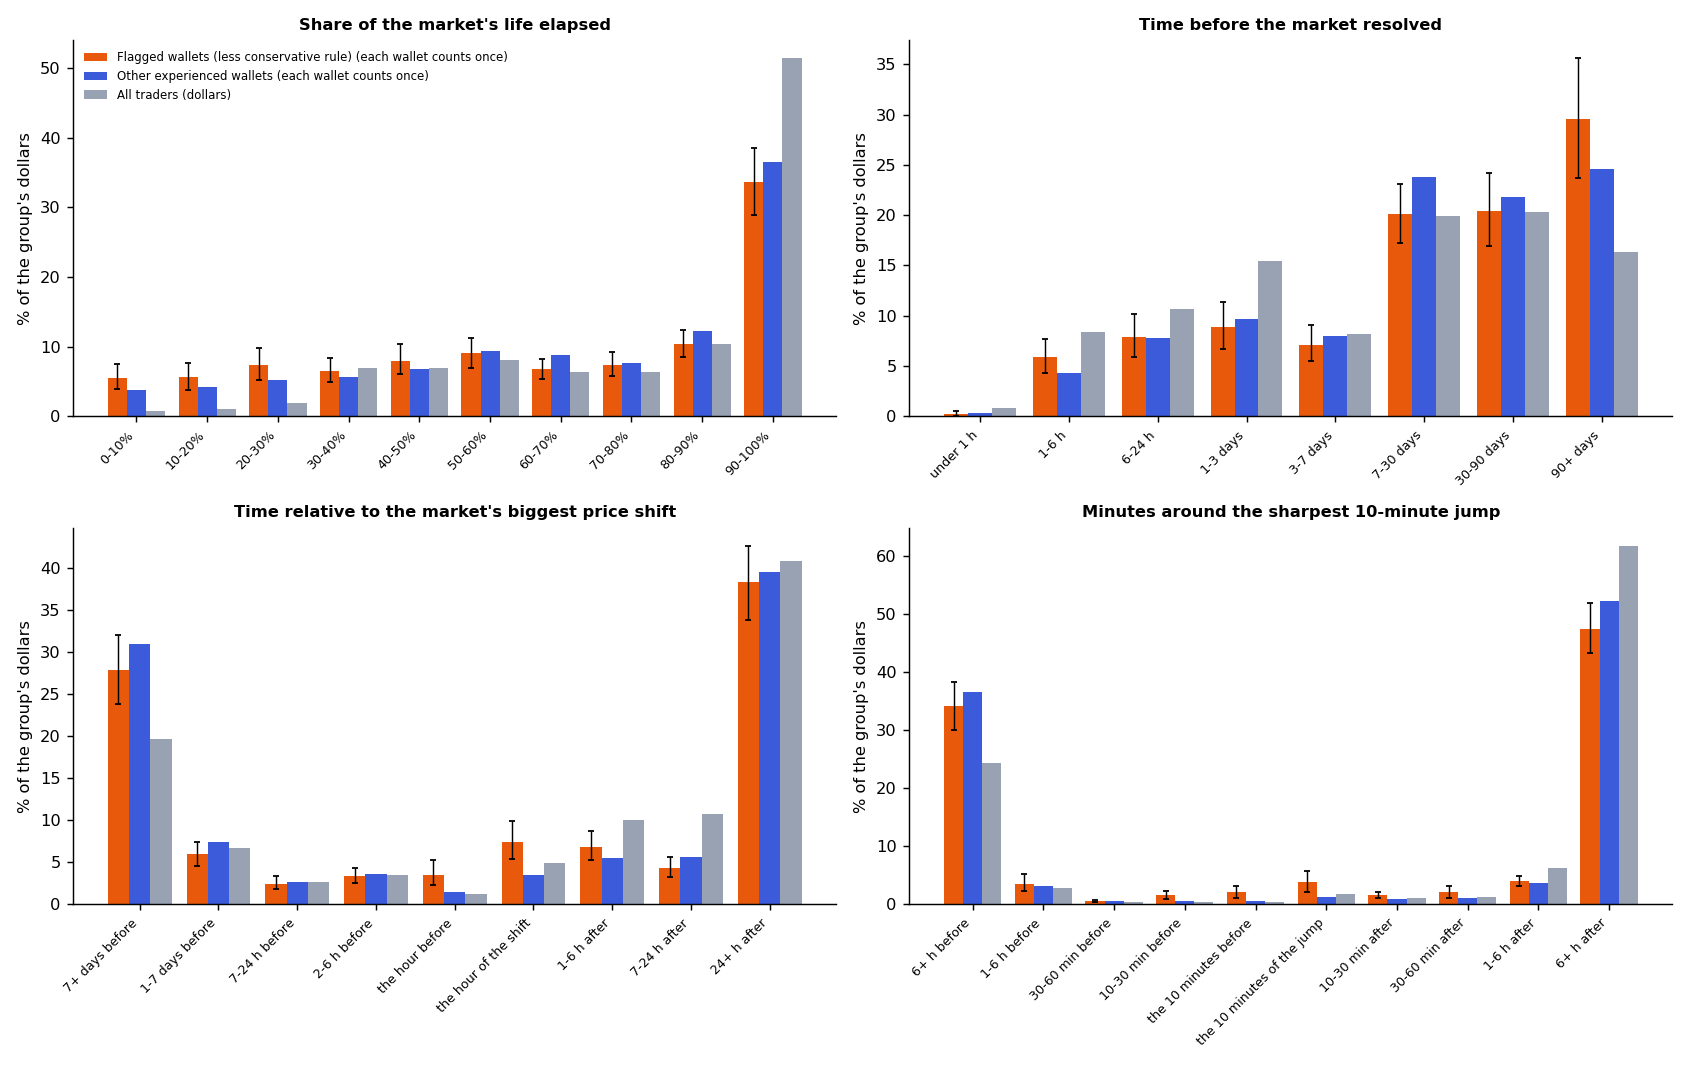

In [43]:
if TIMING_OK:
    display(Image(filename=str(TIMING / "figures" / "timing_clocks.png"), width=900))

**What the clocks show.** Flagged wallets put more of their money **early** (the first tenth of a market's life, and 90+ days before resolution) than other experienced wallets, and **no more** than others in the last hours before resolution. The standout is **around sharp price jumps**: in the 10 minutes before the sharpest jump they place about three times the usual share of their dollars.

**Was that money on the right side, and did it make money?** The next table and charts split each time bucket into dollars on the side the price then moved to (50% is a coin flip) and profit per dollar.

,flagged: wallets,flagged: dollars on the side the price moved to,other experienced: same,flagged: profit per $,other experienced: profit per $
time around the sharpest 10-minute jump,,,,,
1-6 h before,104,61% (50% to 70%),46%,+56% (+31% to +82%),+30%
30-60 min before,71,44% (23% to 66%),55%,-7% (-50% to +38%),+16%
10-30 min before,80,60% (50% to 70%),44%,+25% (-3% to +61%),-9%
the 10 minutes before,83,69% (58% to 79%),47%,+57% (+24% to +98%),+0%
the 10 minutes of the jump,91,75% (52% to 87%),66%,-0% (-20% to +8%),-9%
10-30 min after,82,71% (52% to 83%),71%,+2% (-25% to +20%),-7%
30-60 min after,86,51% (31% to 81%),72%,-32% (-56% to -0%),-14%
1-6 h after,93,63% (46% to 74%),69%,-9% (-33% to +9%),-13%


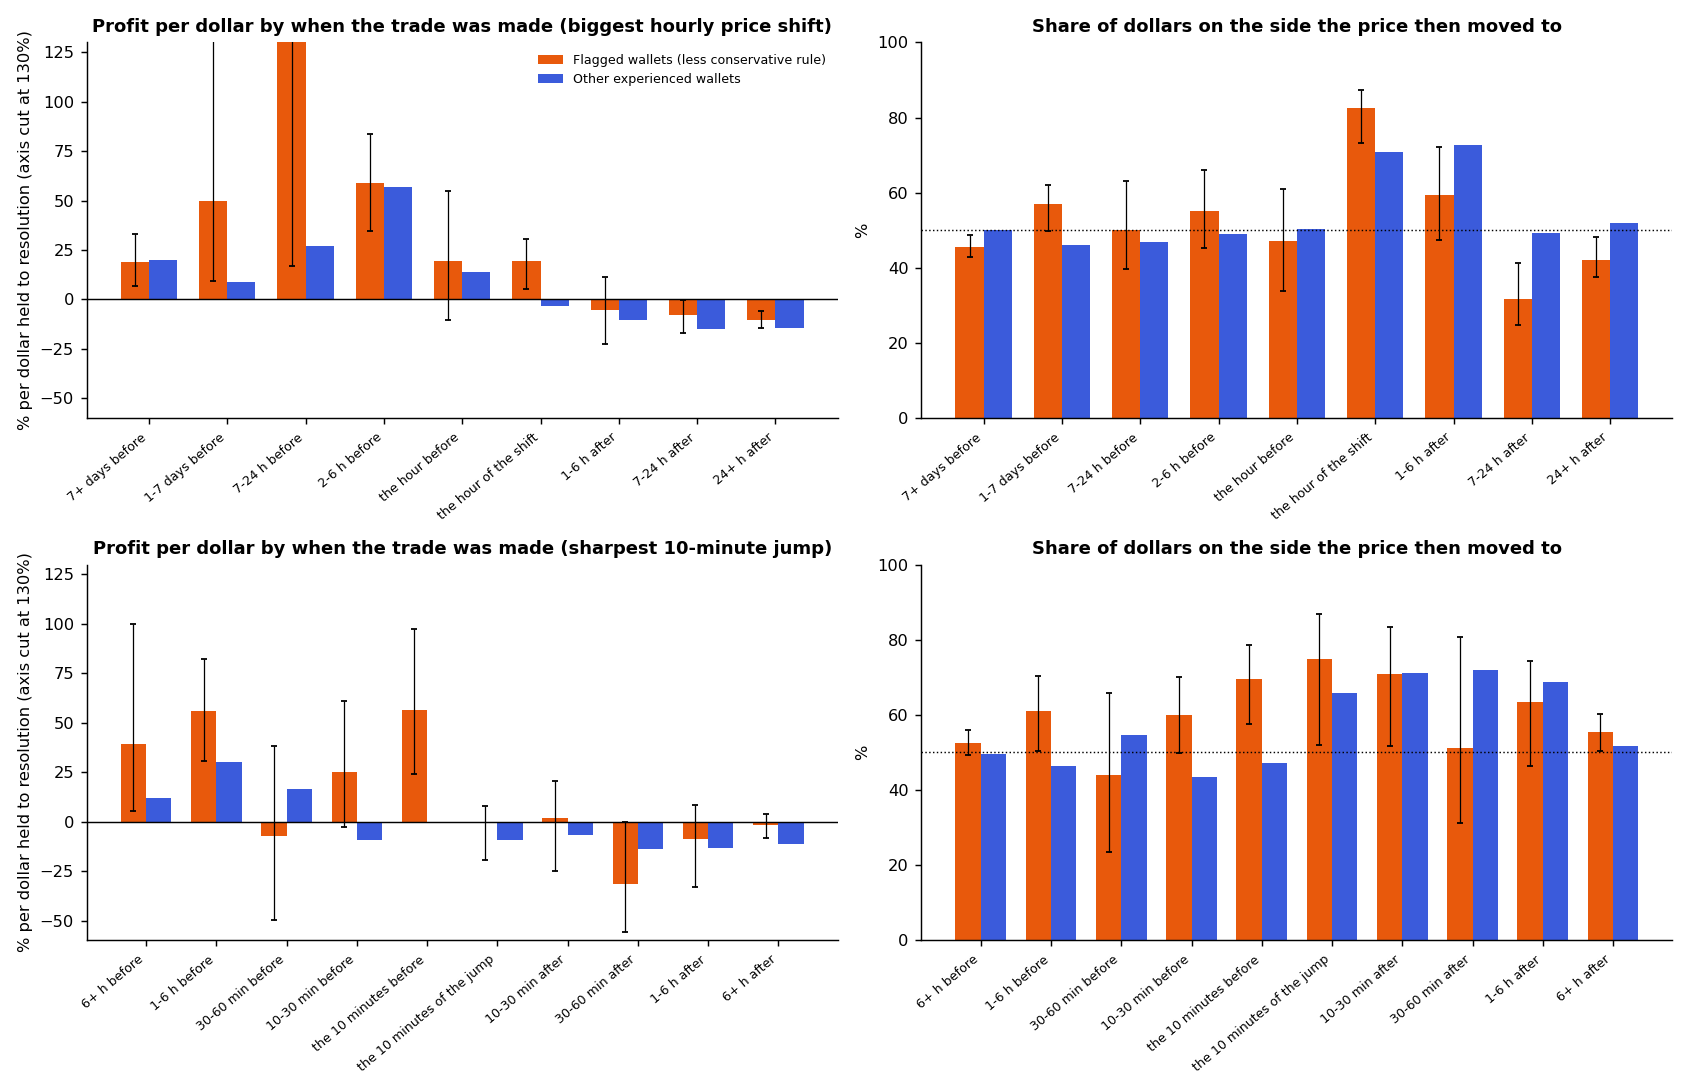

In [44]:
if TIMING_OK:
    rbk = pd.read_csv(TIMING / "timing_by_shift_bucket.csv"); jb = rbk[rbk.clock == "10-minute"]
    order10 = ["1-6 h before", "30-60 min before", "10-30 min before", "the 10 minutes before", "the 10 minutes of the jump", "10-30 min after", "30-60 min after", "1-6 h after"]
    f = jb[jb.group == FG].set_index("bucket").reindex(order10); o = jb[jb.group == OG].set_index("bucket").reindex(order10)
    display(pd.DataFrame({"flagged: wallets": f.wallets.astype(int),
                          "flagged: dollars on the side the price moved to": [f"{v:.0%} ({a:.0%} to {b:.0%})" for v, a, b in zip(f.share_on_shift_side, f.side_lo, f.side_hi)],
                          "other experienced: same": o.share_on_shift_side.map("{:.0%}".format).to_numpy(),
                          "flagged: profit per $": [f"{v:+.0%} ({a:+.0%} to {b:+.0%})" for v, a, b in zip(f.profit_per_dollar, f.ppd_lo, f.ppd_hi)],
                          "other experienced: profit per $": o.profit_per_dollar.map("{:+.0%}".format).to_numpy()}, index=order10).rename_axis("time around the sharpest 10-minute jump"))
    display(Image(filename=str(TIMING / "figures" / "timing_by_shift.png"), width=900))

In [45]:
if TIMING_OK:
    mo = pd.read_csv(TIMING / "timing_markouts.csv"); hz = list(dict.fromkeys(mo.horizon))
    mf = mo[mo.group == FG].set_index("horizon").reindex(hz); mother = mo[mo.group == OG].set_index("horizon").reindex(hz)
    display(pd.DataFrame({"flagged wallets": [f"{v:+.1%} ({a:+.1%} to {b:+.1%})" for v, a, b in zip(mf.gain_per_dollar, mf.lo, mf.hi)],
                          "other experienced wallets": mother.gain_per_dollar.map("{:+.1%}".format).to_numpy()}, index=hz).rename_axis("price move in the trade's favour, per dollar, after..."))
    fo_ = pd.read_csv(TIMING / "timing_fomc.csv")
    if len(fo_):
        pv = fo_.pivot_table(index="bucket", columns="group", values="dollar_share", sort=False).map("{:.1%}".format)
        print("Fed markets, around the FOMC statement (exact release time; share of each group's dollars in Fed markets):"); display(pv)

,flagged wallets,other experienced wallets
"price move in the trade's favour, per dollar, after...",,
5 min,+1.7% (+1.0% to +2.7%),+0.2%
1 hour,+2.1% (+0.6% to +3.5%),+0.1%
6 hours,+4.5% (+2.4% to +7.0%),+0.7%
24 hours,+8.8% (+2.8% to +19.3%),+0.8%
at resolution,+8.0% (-3.8% to +26.5%),-4.7%


Fed markets, around the FOMC statement (exact release time; share of each group's dollars in Fed markets):


group,Flagged wallets (less conservative rule),Other experienced wallets
bucket,,
24+ h before,80.6%,82.6%
6-24 h before,2.3%,8.0%
1-6 h before,6.2%,5.6%
15-60 min before,1.5%,1.3%
0-15 min before,0.9%,1.0%
"after, 0-1 h",6.0%,0.7%
"after, 1+ h",2.5%,0.9%


**Reading the timing results.**
- **When:** flagged wallets trade **early** in a market's life and in **bursts in the minutes before sharp price jumps** (about 3 times others' share; roughly 70% of those dollars on the side the price then moved to, against a coin flip for other wallets, and strongly profitable). They do **not** trade more than others at the last minute before resolution, and after the jump they have **no edge** (fast reaction, not anticipation). In Fed markets they trade mostly more than a day before the statement and react within the hour after it; there is no visible pre-statement trading in the final 15 minutes.
- **After they trade the price moves their way** (about +2% per dollar within an hour, +9% within a day), far more than for other experienced wallets.
- **Caveats.** (1) The signal before jumps is **concentrated**: in fewer than half of the markets where flagged wallets traded in that window did most of their dollars land on the right side, so it comes from a subset of large, well-timed trades. (2) A large buyer who starts pushing the price a few minutes before the jump makes the jump follow its own trades; **information and price impact cannot be separated** here. (3) A positive 5-minute price move can also come from patient limit orders or market making. (4) The flagging rule was chosen after seeing results (step 18). (5) The placebo has not been run through this analysis.

## 22. The updated bottom line

**What we can say.**
- **Timing (step 21):** flagged wallets trade earlier than other wallets and in bursts in the minutes before sharp price jumps (about three times the usual share, mostly on the right side); they show no edge after a jump or in the final hours before resolution. The signal comes from a subset of large trades and could be price impact rather than information.
- **Some wallets keep beating prices.** Wallets flagged on past results beat similar wallets afterwards, on the original 2026 data and on the full history, with the less conservative rule finding about nine times as many wallets as the original rule (a somewhat smaller average edge per wallet). The placebo flags about half as many (less conservative rule), and the simulation shows no false flags when nobody is skilled.
- **A simple rule, "copy trades by wallets whose past score is at least 3 over 10 or more events", earned a small positive return historically:** about +8% per dollar over five separate quarters (interval about +2% to +15%), about +8% in the fresh window (interval about -1% to +18%), against about -4% for random trades in the quarters. Positive in 4 of the 6 periods tested.

**What we cannot say.**
- **That the machine-learning alert model works.** Out of sample it lost money (about -21% pooled) and swung widely between quarters.
- **That "other good wallets agreeing" predicts anything.** The agreement versions look good in some quarters, but the interval spans zero.
- **That any of this is private information.** Persistent outperformance could be skill, speed or patience; the placebo still shows some persistence; some flagged wallets look like bots or market makers.
- **That the return is tradable.** The replay assumes fills at the next observed price with no limit on size; a 1-cent extra cost per share roughly halves the return.

**How to word it.** "Wallets flagged from past results kept outperforming similar wallets afterwards. A simple back-test of copying the wallets with the strongest records returned about 8% per dollar (95% interval about 2% to 15%) over five separate quarters, and a similar figure, not statistically distinguishable from zero, on a fresh window. We do not claim private information, and a trained alert model did not hold up."

**What still has to change in the project files.** The website's Alerts tab and its numbers still describe the first model-based version; they should be rebuilt around the simple rule and should report the model's failure plainly. The flagged-wallet list on the site still uses the original rule (23 wallets); switching to the less conservative rule (207 wallets) is a decision for the team, ideally after one more clean period confirms it.